# AeroFold: attention and antibody discovery

One notebook for public-library reconstruction, cross-family learning, target-trained attention, held-out ranking and candidate screening.

## tl;dr

**Executed on the RTX 3050 Ti GPU across nine antigen-specific tasks and four antibody families**, using 396,688 measured task records. All nine final models fit every finite measurement of their assay. Source learning excludes the complete family being evaluated.

**Attention was trained and tested, then selected by validation.** The two-layer, four-head transformer enters 2 of nine production models and 7 of 36 benchmark fits. Screening-focused ranking trees enter 0 production models. Against the matched attention-free ensemble, attention increases mean recall in 4 of 18 assay/split cases and decreases it in 0; the remaining cases are unchanged. This does not establish universal improvement.

**Measured top-5% recall and enrichment at a fixed budget of 24 variants**, averaged across two seeds. Interpolation is the random split; extrapolation uses strictly higher mutation counts. Complete results:

| Antibody / antigen | Interpolation recall | Extrapolation recall | Interpolation enrichment | Extrapolation enrichment |
| --- | ---: | ---: | ---: | ---: |
| 4-4-20 / fluorescein | 61.5% | 56.2% | 13.13x | 7.08x |
| CH65 / MA90 | 75.0% | 57.7% | 16.00x | 12.31x |
| CH65 / SI06 | 75.0% | 55.8% | 16.00x | 11.90x |
| CH65 / G189E | 73.1% | 48.1% | 15.59x | 10.26x |
| CR9114 / H1 | 48.1% | 30.8% | 10.26x | 6.56x |
| CR9114 / H3 | 78.8% | 76.9% | 16.82x | 16.41x |
| CR9114 / influenza B | 4.7% | 4.7% | 1.00x | 1.00x |
| CR6261 / H1 | 89.5% | 100.0% | 14.09x | 8.71x |
| CR6261 / H9 | 86.8% | 86.4% | 13.35x | 7.48x |

Spearman below includes validation-selected predicted assay-floor ties. Continuous-score correlations are reported in the results table and CSV; for 4-4-20 they are 0.643 for interpolation and 0.309 for extrapolation.

| Antibody / antigen | Interpolation Spearman | Extrapolation Spearman |
| --- | ---: | ---: |
| 4-4-20 / fluorescein | 0.723 | 0.412 |
| CH65 / MA90 | 0.989 | 0.948 |
| CH65 / SI06 | 0.949 | 0.954 |
| CH65 / G189E | 0.985 | 0.944 |
| CR9114 / H1 | 0.968 | 0.913 |
| CR9114 / H3 | 0.805 | 0.913 |
| CR9114 / influenza B | 0.645 | -0.028 |
| CR6261 / H1 | 0.963 | 0.931 |
| CR6261 / H9 | 0.962 | 0.960 |

**Budget ceilings and assay floors matter.** With 26 top-5% positives in a 512-variant test, recall cannot exceed 92.3% when screening 24. Measured boundary ties can increase the positive set. CR9114 influenza B is 99.7% at the assay floor; its top-5% positive set expands to all test variants, enrichment remains 1.00x, and extrapolation Spearman is -0.028. This assay needs more informative affinity measurements.

Source transfer is selected in 0 final production models. Neither source learning nor attention is forced into a blend. All choices use the same frozen inner-validation objective: 40% Spearman and 60% attainable top-24 hits, with random and higher-mutation folds. Outer labels never choose weights.

The notebook executed top to bottom. Source hashes, family exclusions, fold separation, independent metric arithmetic, attention-gate fallback, fresh-process model loading, saved-artifact predictions and batch/token invariance passed. These are retrospective public-library tests already inspected in earlier experiments; seed ranges are descriptive and high-mutation test strata overlap across seeds. Prospective measurements of novel combinations remain the next test.


## Context & Methods
The goal is strong interpolation and higher-mutation discovery measured by Spearman, enrichment and recovery of measured top-5% variants. The ensemble includes additive and nonlinear epistasis models, pair/triple interaction models, ordinal and pairwise ranking, boosting, screening-focused LambdaRank trees, supervised transfer, a target-trained mutation transformer and the verified existing AbLang-2 representation.

### Key Assumptions
Each antigen has a separate prediction task. Cross-family pretraining uses independent assay heads and within-assay labels. **All assays from the evaluated antibody family are excluded from source training**, including untested antigens. Inner validation selects compact mixtures separately for interpolation and mutation-count extrapolation. Internal fitting uses at most 4,000 training and 768 validation examples per fold to bound search cost; selected experts then fit every eligible development measurement. Final models fit every available finite measurement after evaluation. Source pretraining, target neural adaptation and attention train on CUDA; regression and tree fitting use CPU. Training requires an available GPU by default.

Test measurements never select hyperparameters or weights. These are retrospective public libraries, not prospective confirmation. Floor ties are disclosed, and continuous-score correlation is reported alongside floor-aware correlation. At a fixed screening budget, enrichment and recall express the same hit count, so the selection objective counts discovery once: 40% Spearman plus 60% attainable top-24 hit efficiency.


### 1. Setup and reproducible configuration
Use the project `.venv` Python kernel. The default run benchmarks nine antigen assays across all four families using two seeds and trains nine production models. Switch `RUN_BENCHMARK=False` and `TRAIN_FINAL_MODELS=False` to reuse saved evidence and artifacts.

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import math, hashlib, json, time, platform, importlib.metadata, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.optimize import minimize
from scipy.special import expit, log_ndtr, ndtr
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.kernel_approximation import Nystroem
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import linear_kernel
from threadpoolctl import threadpool_limits

AA = '-ACDEFGHIKLMNPQRSTVWY'
CODE = {a:i for i,a in enumerate(AA)}
VERSION = 'aerofold-attention-gpu-5'

def residue_codes(records):
    result = np.zeros((len(records), 360), dtype=np.uint8)
    for i,row in enumerate(records):
        for offset,chain in ((0,'heavy_sequence'),(180,'light_sequence')):
            seq = row.get(chain,'')
            if len(seq)>180 or set(seq)-set(AA[1:]):
                raise ValueError(f'Invalid canonical variable domain: {row.get("variant_id")}')
            result[i,offset:offset+len(seq)] = [CODE[a] for a in seq]
    return result

def consensus(codes):
    return np.array([np.bincount(c,minlength=21).argmax() for c in codes.T])

def fingerprint(row):
    return hashlib.sha256((row['heavy_sequence']+'|'+row['light_sequence']).encode()).hexdigest()

def partition(records,seed,split='random'):
    if len({fingerprint(r) for r in records})!=len(records):
        raise ValueError('Deduplicate exact sequence pairs before splitting')
    rng=np.random.default_rng(seed)
    if split=='random':
        order=rng.permutation(len(records)); nt=max(12,math.ceil(.2*len(records)))
        test,dev=order[:nt],order[nt:]
    elif split=='mutation_extrapolation':
        codes=residue_codes(records); distance=(codes!=consensus(codes)).sum(1)
        cutoff=float(np.quantile(distance,.8))
        test=np.flatnonzero(distance>cutoff)
        dev=rng.permutation(np.flatnonzero(distance<=cutoff))
        if len(test)<12: raise ValueError('Fewer than 12 higher-mutation test variants')
    else: raise ValueError(split)
    if len(dev)<60: raise ValueError('Fewer than 60 unique development variants')
    return dev,test

def metrics(truth,predicted,maximize=True,top_k=24,lower=None,upper=None):
    truth=np.asarray(truth); predicted=np.asarray(predicted)
    assert truth.shape==predicted.shape and np.isfinite(predicted).all()
    direction=1 if maximize else -1; actual=direction*truth
    threshold=np.sort(actual)[-max(1,math.ceil(.05*len(actual)))]; top=actual>=threshold
    k=min(top_k,len(actual)); order=np.argsort(-direction*predicted,kind='stable')[:k]
    hits=int(top[order].sum())
    rho=float(spearmanr(truth,predicted).statistic) if np.ptp(truth)>0 and np.ptp(predicted)>0 else np.nan
    out=dict(spearman=rho,rmse=float(np.sqrt(np.mean((truth-predicted)**2))),
        mae=float(np.mean(np.abs(truth-predicted))),top_recall=hits/int(top.sum()),
        top_enrichment=(hits/k)/float(top.mean()),top_hits=hits,top_population=int(top.sum()),
        top_k=k,test_count=len(truth),random_recall=k/len(truth),random_enrichment=1.)
    if lower is not None:
        out.update(coverage=float(np.mean((truth>=lower)&(truth<=upper))),
            mean_interval_width=float(np.mean(upper-lower)))
    return out






from IPython.display import display, Markdown
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import cloudpickle

ROOT=Path.cwd().resolve()
RESULTS_DIR=ROOT/'results/multifamily';RESULTS_DIR.mkdir(exist_ok=True,parents=True)
CACHE_DIR=ROOT/'cache';CACHE_DIR.mkdir(exist_ok=True)
SEEDS=[314159,271828]
TRANSFER_SEED=731
PRODUCTION_SEED=161803
PRETRAIN_EPOCHS=6
ADAPT_EPOCHS=8
ATTENTION_UPDATES=192
REQUIRE_GPU=True
INNER_TRAIN_LIMIT=4000
INNER_VALID_LIMIT=768
TEST_LIMIT=512
TOP_K=24
SPLITS=['random','mutation_extrapolation']
BENCHMARK_TASKS=['titeseq_4420_binding','ch65_full_ma90_binding','ch65_full_si06_binding','ch65_full_g189e_binding',
    'cr9114_full_h1_binding','cr9114_full_h3_binding','cr9114_full_flub_binding','cr6261_full_h1_binding','cr6261_full_h9_binding']
FINAL_TASKS=BENCHMARK_TASKS.copy()
TRAIN_FINAL_MODELS=True
CANDIDATE_TASK='titeseq_4420_binding'
CANDIDATES_CSV=None
RUN_BENCHMARK=True
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'savefig.bbox':'tight'})
warnings.filterwarnings('ignore',message='X does not have valid feature names',category=UserWarning)
CODE_HASH=hashlib.sha256('\n'.join(c.source for c in __import__('nbformat').read(ROOT/'AeroFold_lab.ipynb',as_version=4).cells if c.cell_type=='code').encode()).hexdigest()
print(f'Python {platform.python_version()} | {VERSION} | full measured libraries, four antibody families')


Python 3.12.14 | aerofold-attention-gpu-5 | full measured libraries, four antibody families


## Data
### 2. Reconstruct original measured libraries
CH65: [original study repository](https://github.com/amphilli/CH65-comblib) and [paper](https://doi.org/10.7554/eLife.83628). CR9114 and CR6261: [original paper source tables](https://elifesciences.org/articles/71393/figures), [analysis repository](https://github.com/klawrence26/bnab-landscapes), and original supplementary plasmids. The existing 4-4-20 CSV is preserved. Genotype bits are checked against every published positional bit and mutation count. Original constructs supply actual variable-domain sequences; linkers and display tags are removed.

The new CR9114 tables cover up to 65,535 measured genotypes rather than the roughly 32,000 in the prior local exports. Different antigen tasks reuse sequences but retain distinct measurements. Missing affinity values are excluded, never assigned zero. Download URLs and byte hashes are locked in `data/raw/download_manifest.json`. Raw sources are included locally; downloads occur only if a listed source is missing.

In [2]:
from Bio import SeqIO
from Bio.Seq import Seq
import yaml
import urllib.request

def ensure_sources():
    manifest = json.loads((ROOT/'data/raw/download_manifest.json').read_text(encoding='utf8'))
    for item in manifest:
        path = ROOT/item['file']
        if not path.exists():
            path.parent.mkdir(parents=True, exist_ok=True)
            path.write_bytes(urllib.request.urlopen(item['url'], timeout=120).read())
        if hashlib.sha256(path.read_bytes()).hexdigest() != item['sha256']:
            raise ValueError(f"Source hash mismatch: {path.name}")
    return manifest

def construct_sequences(name):
    pairs=[]
    for endpoint in ['germline','somatic']:
        plasmid=SeqIO.read(ROOT/f'data/raw/{name}_{endpoint}.dna','snapgene')
        feature=next(f for f in plasmid.features if f.qualifiers.get('label')==['display fragment'])
        protein=str(feature.extract(plasmid.seq).translate())
        # Original yeast-display construct: tags, variable light, linker, variable heavy, Myc.
        prefix='YPYDVPDYALQASGGGGSGGGGSGGGGSAS'
        tail=protein.split(prefix,1)[1].split('EQKLISEEDL',1)[0]
        light,heavy=tail.split('SGGGGSGGGGSGGGGSGGGGSGGGGS',1)
        assert 70<=len(heavy)<=180 and 70<=len(light)<=180
        assert not (set(heavy+light)-set(AA[1:]))
        pairs.append((heavy,light))
    assert pairs[0][1]==pairs[1][1], 'These libraries vary the heavy chain only'
    return pairs

def rebuild_public_assays():
    sources=ensure_sources(); specifications={}; checks=[]
    cfg=yaml.safe_load((ROOT/'data/raw/ch65_config.yaml').read_text(encoding='utf8'))
    ancestral=str(Seq(cfg['ancestral_seq'].strip()).translate())
    descendant=str(Seq(cfg['descendant_seq'].strip()).translate())
    linker='GGGGGSGGGGSGGGGS'
    light,heavy=ancestral.split(linker)
    dl,dh=descendant.split(linker)
    positions=[i for i,(a,b) in enumerate(zip(ancestral,descendant)) if a!=b]
    assert len(positions)==16
    specs=[('ch65',ROOT/'data/raw/ch65_qc.csv','geno',(heavy,light),(dh,dl),
            [('MA90','MA90_mean',['repa_x','repb_x']),('SI06','SI06_mean',['repa_y','repb_y']),('G189E','G189E_mean',['repa','repb'])])]
    for name in ['cr9114','cr6261']:
        start,end=construct_sequences(name)
        antigens=[('h1','h1_mean',['h1_repa','h1_repb','h1_repc'])]
        antigens += [('h3','h3_mean',['h3_repa','h3_repb','h3_repc']),('fluB','fluB_mean',['fluB_repa','fluB_repb','fluB_repc'])] if name=='cr9114' else [('h9','h9_mean',['h9_repa','h9_repb','h9_repc'])]
        specs.append((name,ROOT/f'data/raw/{name}.csv','genotype',start,end,antigens))
    for family,path,genocol,start,end,antigens in specs:
        raw=pd.read_csv(path,dtype={genocol:str},keep_default_na=False,low_memory=False)
        if family=='ch65':
            # The published bit order follows VL-GS-VH, not heavy-first order.
            mutations=[('light_sequence',i,a,b) for i,(a,b) in enumerate(zip(start[1],end[1])) if a!=b]
            mutations += [('heavy_sequence',i,a,b) for i,(a,b) in enumerate(zip(start[0],end[0])) if a!=b]
        else:
            mutations=[('heavy_sequence',i,a,b) for i,(a,b) in enumerate(zip(start[0],end[0])) if a!=b]
        assert len(mutations)==(11 if family=='cr6261' else 16)
        bitcols=[f'pos{i+1}' for i in range(len(mutations))]
        bits=raw[bitcols].apply(pd.to_numeric).to_numpy(dtype=np.uint8)
        genotype=raw[genocol].str.zfill(len(mutations))
        assert np.array_equal(bits,np.array([list(s) for s in genotype],dtype=np.uint8))
        assert np.array_equal(bits.sum(1),pd.to_numeric(raw.som_mut).to_numpy())
        sequence_rows=[]
        for binary in bits:
            chains={'heavy_sequence':list(start[0]),'light_sequence':list(start[1])}
            for active,(chain,pos,a,b) in zip(binary,mutations):
                assert chains[chain][pos]==a
                if active: chains[chain][pos]=b
            sequence_rows.append({chain:''.join(seq) for chain,seq in chains.items()})
        base=pd.DataFrame(sequence_rows)
        base['variant_id']=family.upper()+'-'+genotype
        base['sequence_sha256']=[fingerprint(r) for r in base.to_dict('records')]
        assert not base.sequence_sha256.duplicated().any()
        for antigen,column,reps in antigens:
            score=pd.to_numeric(raw[column],errors='coerce')
            valid=np.isfinite(score)
            task=f'{family}_full_{antigen.lower()}_binding'
            frame=base.loc[valid].copy();frame['score']=score[valid].to_numpy()
            frame['replicate_count']=raw.loc[valid,reps].apply(pd.to_numeric,errors='coerce').notna().sum(axis=1).to_numpy()
            frame['measurement_sem']=pd.to_numeric(raw.loc[valid,column.replace('_mean','_sem')],errors='coerce').to_numpy()
            frame['mutations_from_ancestor']=bits[valid].sum(1)
            frame.to_csv(ROOT/f'data/{task}.csv',index=False)
            specifications[task]=dict(family=family,antigen=antigen,reference_heavy=start[0],reference_light=start[1],
                score='pKd = -log10(Kd in M); higher is better',source=str(path.relative_to(ROOT)),
                mutations=[dict(chain=c,position_zero_based=p,ancestral=a,descendant=b) for c,p,a,b in mutations])
            checks.append(dict(task=task,source_rows=len(raw),finite_measured_rows=len(frame),unique_sequences=frame.sequence_sha256.nunique(),
                floor_fraction=float((score[valid]==score[valid].min()).mean()),max_mutations=int(bits[valid].sum(1).max())))
    original=pd.read_csv(ROOT/'data/titeseq_4420_binding.csv',keep_default_na=False)
    c=consensus(residue_codes(original.to_dict('records')))
    specifications['titeseq_4420_binding']=dict(family='4420',antigen='fluorescein',reference_heavy=''.join(AA[a] for a in c[:180] if a),
        reference_light=''.join(AA[a] for a in c[180:] if a),score='Original local pKd; higher is better',source='data/titeseq_4420_binding.csv')
    (RESULTS_DIR/'dataset_provenance.json').write_text(json.dumps(dict(sources=sources,tasks=specifications,checks=checks),indent=2),encoding='utf8')
    return specifications,pd.DataFrame(checks)

TASK_INFO,conversion_audit=rebuild_public_assays()
data={};source_rows=[]
for task,info in TASK_INFO.items():
    path=ROOT/f'data/{task}.csv';frame=pd.read_csv(path,keep_default_na=False)
    frame['key']=[fingerprint(r) for r in frame.to_dict('records')]
    assert frame.key.is_unique and np.isfinite(frame.score).all()
    assert (frame.key==frame.sequence_sha256).all()
    data[task]=frame
    source_rows.append(dict(task=task,family=info['family'],antigen=info['antigen'],rows=len(frame),sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
        floor_fraction=float((frame.score==frame.score.min()).mean()),source=str(path.relative_to(ROOT))))
source_audit=pd.DataFrame(source_rows);source_audit.to_csv(RESULTS_DIR/'data_audit.csv',index=False)
display(source_audit[['task','rows','floor_fraction']].round(3))


,task,rows,floor_fraction
0,ch65_full_ma90_binding,65530,0.000
1,ch65_full_si06_binding,64619,0.488
2,ch65_full_g189e_binding,63840,0.148
3,cr9114_full_h1_binding,65094,0.026
4,cr9114_full_h3_binding,65535,0.891
5,cr9114_full_flub_binding,65534,0.997
6,cr6261_full_h1_binding,1887,0.113
7,cr6261_full_h9_binding,1842,0.202
8,titeseq_4420_binding,2807,0.736


### 3. Inspect coverage and measurement limits

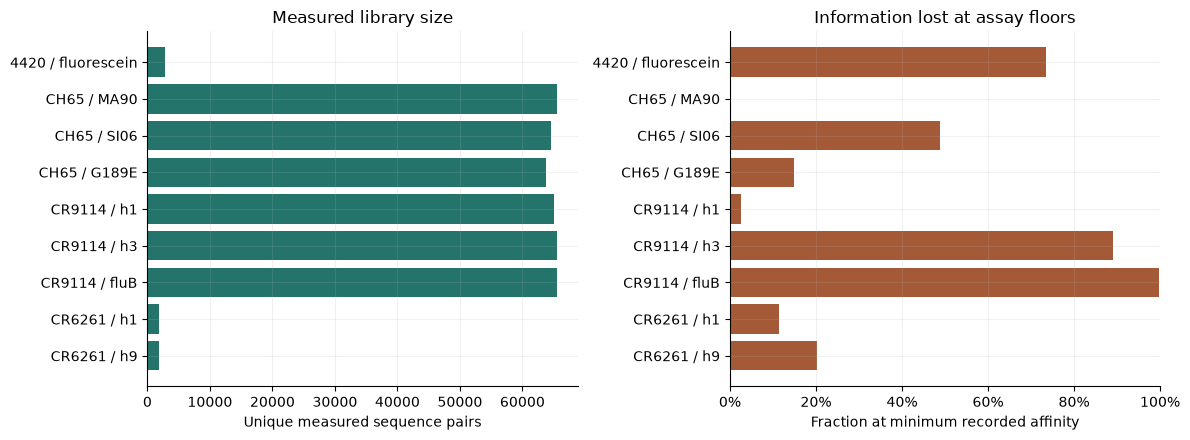

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
audit=source_audit.set_index('task').reindex(BENCHMARK_TASKS)
names=[TASK_INFO[t]['family'].upper()+' / '+TASK_INFO[t]['antigen'] for t in BENCHMARK_TASKS]
axes[0].barh(names,audit.rows,color='#24746c');axes[0].set(xlabel='Unique measured sequence pairs',title='Measured library size');axes[0].invert_yaxis()
axes[1].barh(names,audit.floor_fraction,color='#a55a37');axes[1].set(xlabel='Fraction at minimum recorded affinity',title='Information lost at assay floors',xlim=(0,1));axes[1].invert_yaxis();axes[1].xaxis.set_major_formatter(PercentFormatter(1))
fig.tight_layout();fig.savefig(RESULTS_DIR/'data_coverage.png',dpi=160);plt.show()


### 4. Assay features and ranking losses
Mutation chemistry and local sequence context support sharing across families. Position bins are fractions of chain length; they do not assert IMGT equivalence. Pair and triple terms capture interactions in the measured combinatorial libraries. Feature scalers and observed allele columns are fitted on training examples only.

In [4]:
class SequenceFeatures:
    """Training-only mutation contrasts plus shared biochemical substitution priors."""
    def fit(self,codes):
        self.reference=consensus(codes)
        self.variable=np.flatnonzero(np.any(codes!=self.reference,axis=0))
        self.property_table=np.zeros((21,5))
        # Hydrophobicity, volume, charge, aromaticity, glycine/proline indicator.
        hydro=[1.8,2.5,-3.5,-3.5,2.8,-.4,-3.2,4.5,-3.9,3.8,1.9,-3.5,-1.6,-3.5,-4.5,-.8,-.7,4.2,-.9,-1.3]
        volume=[88.6,108.5,111.1,138.4,189.9,60.1,153.2,166.7,168.6,166.7,162.9,114.1,112.7,143.8,173.4,89.,116.1,140.,227.8,193.6]
        for i,a in enumerate(AA[1:],1):
            self.property_table[i]=[hydro[i-1]/4.5,volume[i-1]/200.,1 if a in 'KR' else -1 if a in 'DE' else .1 if a=='H' else 0,float(a in 'FWY'),float(a in 'GP')]
        self.scaler=StandardScaler().fit(self._properties(codes))
        return self

    def _properties(self,codes):
        p=self.property_table[codes]-self.property_table[self.reference][None]
        mismatch=codes!=self.reference
        counts=np.column_stack([mismatch[:,:180].sum(1),mismatch[:,180:].sum(1)])
        totals=np.column_stack([p[:,:180].sum(1),p[:,180:].sum(1),counts])
        site=p[:,self.variable].reshape(len(codes),-1)
        return np.column_stack([site,totals])

    def transform(self,codes,augmented=False):
        rows,pos=np.where(codes!=self.reference)
        x=sparse.csr_matrix((np.r_[np.ones(len(rows)),-np.ones(len(rows))],
            (np.r_[rows,rows],np.r_[pos*21+codes[rows,pos],pos*21+self.reference[pos]])),shape=(len(codes),7560))
        if augmented:
            # Weak shared prior; rare/unknown substitutions can borrow biochemical signal.
            return sparse.hstack([x,.15*sparse.csr_matrix(self.scaler.transform(self._properties(codes)))],format='csr')
        return x

In [5]:
class GlobalEpistasis(RegressorMixin,BaseEstimator):
    """A regularized latent additive trait mapped through a monotone sigmoid."""
    def __init__(self,alpha=.01): self.alpha=alpha
    def fit(self,x,y):
        self.low=float(np.min(y)); self.high=float(np.max(y)); self.span=max(self.high-self.low,1e-6)
        t=np.clip((y-self.low)/self.span,.015,.985)
        initial=Ridge(alpha=1.,solver='lsqr',tol=1e-6).fit(x,np.log(t/(1-t)))
        start=np.r_[initial.coef_,initial.intercept_]
        def objective(theta):
            z=np.asarray(x@theta[:-1]).ravel()+theta[-1]; p=expit(z); e=p-(y-self.low)/self.span
            deriv=2*e*p*(1-p)/len(y)
            loss=np.mean(e*e)+self.alpha*np.dot(theta[:-1],theta[:-1])/len(y)
            grad=np.r_[np.asarray(x.T@deriv).ravel()+2*self.alpha*theta[:-1]/len(y),deriv.sum()]
            return loss,grad
        result=minimize(objective,start,jac=True,method='L-BFGS-B',options={'maxiter':350,'ftol':1e-10})
        if not np.isfinite(result.fun): raise ValueError('Global epistasis did not converge to a finite solution')
        self.theta=result.x; self.converged=bool(result.success); self.fitted_=True
        return self
    def predict(self,x):
        return self.low+self.span*expit(np.asarray(x@self.theta[:-1]).ravel()+self.theta[-1])

class CensoredAdditive(RegressorMixin,BaseEstimator):
    """Gaussian Tobit at repeated training endpoints, with expected observed score."""
    def __init__(self,alpha=1.,sigma=.5): self.alpha,self.sigma=alpha,sigma
    def fit(self,x,y):
        self.mean=float(np.mean(y)); self.scale=max(float(np.std(y)),1e-6); t=(y-self.mean)/self.scale
        low,high=float(np.min(t)),float(np.max(t))
        self.low=low if np.sum(t==low)>=max(5,.05*len(t)) else -np.inf
        self.high=high if np.sum(t==high)>=max(5,.05*len(t)) else np.inf
        left=t<=self.low; right=t>=self.high; middle=~(left|right)
        initial=Ridge(alpha=self.alpha,solver='lsqr',tol=1e-6).fit(x,t)
        def objective(theta):
            mu=np.asarray(x@theta[:-1]).ravel()+theta[-1]; d=np.zeros(len(t)); loss=np.zeros(len(t)); s=self.sigma
            e=(mu[middle]-t[middle])/s; loss[middle]=.5*e*e; d[middle]=e/s
            for mask,sign,bound in ((left,-1,self.low),(right,1,self.high)):
                if np.any(mask):
                    z=sign*(mu[mask]-bound)/s; lc=log_ndtr(z)
                    loss[mask]=-lc; d[mask]=-sign*np.exp(-.5*z*z-.5*np.log(2*np.pi)-lc)/s
            val=loss.mean()+.5*self.alpha*np.dot(theta[:-1],theta[:-1])/len(t)
            grad=np.r_[(np.asarray(x.T@d).ravel()+self.alpha*theta[:-1])/len(t),d.mean()]
            return val,grad
        result=minimize(objective,np.r_[initial.coef_,initial.intercept_],jac=True,method='L-BFGS-B',options={'maxiter':300,'ftol':1e-9})
        if not np.isfinite(result.fun): raise ValueError('Censored additive optimizer failed')
        self.theta=result.x; self.converged=bool(result.success); self.fitted_=True
        return self
    def predict(self,x):
        mu=np.asarray(x@self.theta[:-1]).ravel()+self.theta[-1]; s=self.sigma
        # E[max(Z, floor)] and E[min(Z, ceiling)] under Z ~ N(mu,sigma^2).
        ans=mu.copy()
        if np.isfinite(self.low):
            z=(self.low-mu)/s; ans+=(self.low-mu)*ndtr(z)+s*np.exp(-.5*z*z)/np.sqrt(2*np.pi)
        if np.isfinite(self.high):
            z=(mu-self.high)/s; ans-=(mu-self.high)*ndtr(z)+s*np.exp(-.5*z*z)/np.sqrt(2*np.pi)
        return self.mean+self.scale*ans

class HurdleModel:
    """Separate probability of escaping an observed assay floor from active score."""
    def __init__(self,alpha=1.): self.alpha=alpha
    def fit(self,x,y):
        self.floor=float(np.min(y)); active=y>self.floor+1e-8
        self.fallback=Ridge(alpha=self.alpha,solver='lsqr').fit(x,y)
        self.enabled=int(active.sum())>=12 and int((~active).sum())>=12
        if self.enabled:
            self.classifier=LogisticRegression(C=1/self.alpha,max_iter=600,solver='lbfgs').fit(x,active)
            self.regression=Ridge(alpha=self.alpha,solver='lsqr').fit(x[active],y[active])
            self.ceiling=float(np.max(y))
        return self
    def predict(self,x):
        if not self.enabled: return self.fallback.predict(x)
        p=self.classifier.predict_proba(x)[:,1]
        return self.floor+p*(np.clip(self.regression.predict(x),self.floor,self.ceiling)-self.floor)

class ExactSequenceKernel:
    """Exact, small-data kernel with an explicit additive component retained."""
    def __init__(self,alpha=1.,interaction=.1,local=False):
        self.alpha,self.interaction,self.local=alpha,interaction,local
    def kernel(self,a,b):
        g=linear_kernel(a,b)
        if self.local:
            d=np.maximum(0,np.asarray(a.multiply(a).sum(1))+np.asarray(b.multiply(b).sum(1)).T-2*g)
            return g+self.interaction*self.norm*np.exp(-d/self.norm)
        return g+self.interaction*g*g/self.norm
    def fit(self,x,y):
        self.x=x; self.mean=float(np.mean(y)); self.norm=max(2.,float(x.multiply(x).sum(1).mean()))
        k=self.kernel(x,x); k.flat[::len(y)+1]+=self.alpha
        from scipy.linalg import solve
        self.dual=solve(k,y-self.mean,assume_a='pos')
        return self
    def predict(self,x): return self.mean+self.kernel(x,self.x)@self.dual

In [6]:
from scipy.stats import rankdata
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.isotonic import IsotonicRegression

class PairwiseRanker:
    """Regularized RankNet linear utility; tied pairs never create artificial order."""
    def __init__(self,alpha=1.,tail_weight=0.,seed=913):
        self.alpha,self.tail_weight,self.seed=alpha,tail_weight,seed
    def fit(self,x,y):
        n=len(y); rng=np.random.default_rng(self.seed)
        i=rng.integers(n,size=min(100000,80*n)); j=rng.integers(n,size=len(i))
        mask=y[i]!=y[j]; i,j=i[mask],j[mask]
        positive=y[i]>y[j]; hi=np.where(positive,i,j); lo=np.where(positive,j,i)
        cutoff=np.quantile(y,.95)
        weight=1+self.tail_weight*((y[hi]>=cutoff)&(y[lo]<cutoff))
        weight=weight/max(float(weight.sum()),1.)
        def objective(w):
            utility=np.asarray(x@w).ravel(); diff=utility[hi]-utility[lo]
            loss=float(weight@np.logaddexp(0,-diff))+.5*self.alpha*np.dot(w,w)/n
            slope=-weight*expit(-diff)
            g=np.bincount(hi,weights=slope,minlength=n)-np.bincount(lo,weights=slope,minlength=n)
            return loss,np.asarray(x.T@g).ravel()+self.alpha*w/n
        result=minimize(objective,np.zeros(x.shape[1]),jac=True,method='L-BFGS-B',options={'maxiter':200,'ftol':1e-8})
        if not np.isfinite(result.fun): raise RuntimeError('Nonfinite ranking fit')
        self.coef_=result.x; self.converged=bool(result.success)
        return self
    def predict(self,x): return np.asarray(x@self.coef_).ravel()

class OrdinalRanker:
    """Cumulative binding probabilities; thresholds are learned from training labels."""
    def __init__(self,alpha=1.,tail_weight=1.): self.alpha,self.tail_weight=alpha,tail_weight
    def fit(self,x,y):
        self.thresholds=np.unique(np.quantile(y,[0,.25,.5,.75,.85,.9,.95]))
        self.models=[]; self.weights=[]
        for threshold in self.thresholds:
            target=y>threshold
            if min(target.sum(),(~target).sum())<5: continue
            model=LogisticRegression(C=1/self.alpha,max_iter=500,solver='lbfgs').fit(x,target)
            self.models.append(model)
            self.weights.append(1+self.tail_weight*float(threshold>=np.quantile(y,.85)))
        self.weights=np.asarray(self.weights,float)
        if not self.models:
            self.fallback=Ridge(alpha=self.alpha,solver='lsqr').fit(x,y)
        return self
    def predict(self,x):
        if not self.models: return self.fallback.predict(x)
        return np.column_stack([m.predict_proba(x)[:,1] for m in self.models])@self.weights/self.weights.sum()

class RankTargetRidge:
    def __init__(self,alpha=1.): self.alpha=alpha
    def fit(self,x,y):
        self.model=Ridge(alpha=self.alpha,solver='lsqr',tol=1e-6).fit(x,(rankdata(y)-.5)/len(y))
        return self
    def predict(self,x): return self.model.predict(x)

class LambdaRankHead:
    """One target/assay is one ranking query; ordered measurement bins retain ties."""
    def __init__(self,leaves=7,regularization=10.): self.leaves,self.regularization=leaves,regularization
    def fit(self,x,y):
        from lightgbm import LGBMRanker
        # Keep repeated endpoint measurements in one relevance bin.
        thresholds=np.unique(np.quantile(y,np.linspace(0,1,17)))
        relevance=np.searchsorted(thresholds,y,side='left').astype(int)
        self.model=LGBMRanker(objective='lambdarank',n_estimators=220,num_leaves=int(self.leaves),
            learning_rate=.04,min_child_samples=12,reg_lambda=self.regularization,
            lambdarank_truncation_level=30,label_gain=list(np.arange(len(thresholds)+1,dtype=float)**2),
            verbosity=-1,n_jobs=2,random_state=913)
        self.model.fit(pd.DataFrame(x),relevance,group=[len(y)],categorical_feature=list(range(x.shape[1])))
        return self
    def predict(self,x): return self.model.predict(pd.DataFrame(x))

class RankKernel:
    def __init__(self,alpha=1.,interaction=1.): self.alpha,self.interaction=alpha,interaction
    def fit(self,x,y):
        self.model=ExactSequenceKernel(self.alpha,self.interaction).fit(x,(rankdata(y)-.5)/len(y))
        return self
    def predict(self,x): return self.model.predict(x)
def rank_utility(y,p):
    m=metrics(y,p)
    rho=m['spearman'] if np.isfinite(m['spearman']) else 0.
    efficiency=m['top_hits']/min(m['top_k'],m['top_population'])
    return .4*rho+.6*efficiency

def rank_scale(values,center,scale):
    # Strictly monotone with smooth tails; predictions do not depend on query batch composition.
    return .5+np.arctan((values-center)/scale)/np.pi

### 5. Validation-selected ensembles
Small mixtures and assay-floor cutoffs are chosen from internal validation. Both continuous and floor-aware scores are retained so gains from predicting censored ties remain visible.

In [7]:
def supported_distance(counts):
    levels,number=np.unique(counts,return_counts=True)
    supported=levels[number>=max(5,math.ceil(.02*len(counts)))]
    return int(supported.max()) if len(supported) else int(np.max(counts))

def floor_aware_score(raw,cut):
    return np.maximum(0.,np.asarray(raw)-cut)/(1-cut)

def choose_blend(blocks,regime,n_heads,allow_floor_ties=False):
    """Small, regularized blends chosen only with inner validation measurements."""
    has_shift=any(b['name']=='higher_mutation' for b in blocks)
    cuts=[0.,.25,.35,.4,.45,.5,.55] if allow_floor_ties else [0.]
    def quality(weights):
        mixtures=[b['prediction']@weights for b in blocks]; results=[]
        for cut in cuts:
            random=[]; shifted=[]
            for b,p in zip(blocks,mixtures):
                score=rank_utility(b['y'],floor_aware_score(p,cut))
                (shifted if b['name']=='higher_mutation' else random).append(score)
            random=np.asarray(random); stable=float(random.mean()-.1*random.std())
            fraction=(.75 if regime=='extrapolation' else .25) if has_shift else 0.
            results.append((1-fraction)*stable+fraction*(float(np.mean(shifted)) if shifted else 0.))
        # Prefer the less aggressive cutoff unless the gain exceeds .005.
        best=0
        for i in range(1,len(cuts)):
            if results[i]>results[best]+.005: best=i
        return float(results[best]),cuts[best]
    eye=np.eye(n_heads); single=[quality(w) for w in eye]
    individual=np.array([v[0] for v in single]); individual_cuts=np.array([v[1] for v in single])
    best=int(np.argmax(individual)); weights=eye[best].copy(); value=float(individual[best]); cut=float(individual_cuts[best])
    shortlist=np.argsort(-individual)[:10]
    for _ in range(2):
        trial_best=None; trial_value=value
        for j in shortlist:
            for amount in [.2,.4,.6]:
                w=(1-amount)*weights+amount*eye[j]
                score,new_cut=quality(w)
                if score>trial_value+.008:
                    trial_best,trial_value,trial_cut=w,score,new_cut
        if trial_best is None: break
        weights,value,cut=trial_best,trial_value,trial_cut
    return weights,value,individual,cut,individual_cuts



### 6. Reuse verified foundation embeddings
The existing paired AbLang-2 cache is used only for 4-4-20. No fabricated embeddings or automatic checkpoint substitution are used.

In [8]:
embeddings={}
task='titeseq_4420_binding';frame=data[task]
data_hash=hashlib.sha256((ROOT/f'data/{task}.csv').read_bytes()).hexdigest()
cache=CACHE_DIR/f'{task}_ablang2_{data_hash[:12]}.npz'
if cache.exists():
    with np.load(cache,allow_pickle=False) as z:
        assert str(z['data_sha256'])==data_hash
        assert str(z['encoder_signature'])=='paired-seqcoding-v1-ablang2-paired'
        assert np.array_equal(z['sequence_keys'],frame.key.to_numpy(dtype=str))
        embeddings[task]=z['embeddings']
    print('Reused real paired AbLang-2 embeddings:',embeddings[task].shape)
else:print('No verified AbLang-2 cache; sequence and supervised transfer models remain available.')


Reused real paired AbLang-2 embeddings: (2807, 480)


### 7. Supervised learning across other antibody families
The shared neural encoder learns from mutation identities, biochemical changes, position bins and local context. Separate source heads prevent incompatible antigen labels from being mixed. All source rows enter every epoch, with equal total loss weight per assay. Each held-out family receives its own source checkpoint. Target adaptation and matched training from scratch use only the current training fold.

In [9]:
import copy
import torch
from torch import nn
from sklearn.preprocessing import PolynomialFeatures

torch.set_num_threads(2)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if REQUIRE_GPU and (RUN_BENCHMARK or TRAIN_FINAL_MODELS) and DEVICE.type!='cuda':
    raise RuntimeError('GPU training is required. Install the CUDA build from requirements.txt and restart the kernel.')
torch.use_deterministic_algorithms(True)
if DEVICE.type=='cuda':
    # Math attention and a fixed cuBLAS workspace keep this small model deterministic.
    torch.backends.cuda.enable_flash_sdp(False)
    torch.backends.cuda.enable_mem_efficient_sdp(False)
    torch.backends.cuda.enable_cudnn_sdp(False)
    torch.backends.cuda.matmul.allow_tf32=False
    torch.backends.cudnn.allow_tf32=False
    print(f'Neural training device: {torch.cuda.get_device_name(0)} | CUDA {torch.version.cuda} | {torch.__version__}')
else:print('CPU inference mode; GPU-required training is disabled.')

def reference_codes(task):
    info=TASK_INFO[task]
    return residue_codes([dict(variant_id='reference',heavy_sequence=info['reference_heavy'],light_sequence=info['reference_light'])])[0]

def semantic_features(codes,reference):
    """Family-independent substitution identities, chemistry, position bins and local context.

    Positions are fractions of each actual chain length, not asserted IMGT equivalences.
    No assay labels or query-batch statistics enter these features.
    """
    helper=SequenceFeatures().fit(reference[None]);properties=helper.property_table
    changed=codes!=reference;rows,pos=np.where(changed)
    chain=pos//180;relative=pos%180
    lengths=np.array([np.count_nonzero(reference[:180]),np.count_nonzero(reference[180:])])
    if any(np.any((codes[:,c*180:(c+1)*180]!=0).sum(axis=1)!=lengths[c]) for c in [0,1]):
        raise ValueError('This transferable mutation encoder requires the reference chain layout')
    bins=np.minimum(7,(relative*8/np.maximum(1,lengths[chain])).astype(int))+8*chain
    n=len(codes);out=np.zeros((n,400+80+80+40+2+20),dtype=np.float32)
    src=reference[pos]-1;dst=codes[rows,pos]-1
    if np.any(src<0)|np.any(dst<0): raise ValueError('Substitution encoder does not support indels')
    np.add.at(out,(rows,src*20+dst),1.)
    delta=properties[codes[rows,pos]]-properties[reference[pos]]
    for p in range(5):
        np.add.at(out,(rows,400+bins*5+p),delta[:,p])
        # Reference local chemistry supplies context for transferring mutation effects.
        neighbour=np.zeros(len(rows))
        for shift in [-2,-1,1,2]:
            at=np.clip(pos+shift,chain*180,chain*180+np.maximum(1,lengths[chain])-1)
            neighbour+=properties[reference[at],p]/4
        np.add.at(out,(rows,480+bins*5+p),delta[:,p]*neighbour)
    for c in [0,1]:
        a=codes[:,c*180:(c+1)*180]
        for k in range(1,21): out[:,560+c*20+k-1]=(a==k).sum(1)/max(1,lengths[c])
        out[:,600+c]=changed[:,c*180:(c+1)*180].sum(1)/10
    for k in range(1,21):
        mask=codes==k;out[:,602+k-1]=(mask&changed).sum(1)/10
    # Counts are bounded smoothly; composition and chemistry retain the direction of substitutions.
    out[:,:400]/=4
    out[:,400:560]/=4
    assert np.isfinite(out).all()
    return out

class SharedMutationNet(nn.Module):
    """Supervised shared representation with independent antigen/assay heads."""
    def __init__(self,input_size=622,tasks=1):
        super().__init__()
        self.encoder=nn.Sequential(nn.Linear(input_size,96),nn.Tanh(),nn.Linear(96,48),nn.Tanh())
        self.head=nn.Linear(48,tasks)
    def forward(self,x,task=None):
        h=self.encoder(x);p=self.head(h)
        return p if task is None else p.gather(1,task[:,None]).ravel()

def neural_loss(pred,y):
    mse=4*torch.mean((pred-y)**2)
    other=torch.roll(y,1);keep=y!=other
    if keep.any():
        sign=torch.sign(y-other);diff=pred-torch.roll(pred,1)
        return mse+.15*torch.nn.functional.softplus(-8*sign[keep]*diff[keep]).mean()
    return mse

def pretrain_excluding(family):
    tasks=[task for task in sorted(data) if TASK_INFO[task]['family']!=family]
    assert all(TASK_INFO[t]['family']!=family for t in tasks)
    signature=hashlib.sha256((CODE_HASH+'|'+family+'|'+source_audit.to_json()).encode()).hexdigest()
    path=CACHE_DIR/f'transfer_{family}_{signature[:16]}.pt'
    if path.exists():
        checkpoint=torch.load(path,map_location='cpu',weights_only=False)
        assert checkpoint['signature']==signature
        print(f'Reused supervised transfer checkpoint excluding {family}')
        return checkpoint
    torch.manual_seed(TRANSFER_SEED)
    model=SharedMutationNet(tasks=len(tasks)).to(DEVICE)
    if DEVICE.type=='cuda':torch.cuda.reset_peak_memory_stats()
    optimizer=torch.optim.AdamW(model.parameters(),lr=.0015,weight_decay=.005)
    arrays=[];task_ids=[];targets=[];weights=[];task_audit=[]
    for j,task in enumerate(tasks):
        frame=data[task];codes=residue_codes(frame.to_dict('records'))
        arrays.append(semantic_features(codes,reference_codes(task)))
        targets.append(((rankdata(frame.score.to_numpy(float))-.5)/len(frame)).astype(np.float32))
        task_ids.append(np.full(len(frame),j,dtype=np.int64));weights.append(np.full(len(frame),1/len(frame),dtype=np.float32))
        task_audit.append(dict(task=task,family=TASK_INFO[task]['family'],rows=len(frame),data_sha256=source_audit.set_index('task').loc[task,'sha256']))
    x=torch.from_numpy(np.concatenate(arrays)).to(DEVICE);y=torch.from_numpy(np.concatenate(targets)).to(DEVICE);t=torch.from_numpy(np.concatenate(task_ids)).to(DEVICE)
    weight=torch.from_numpy(np.concatenate(weights)).to(DEVICE);weight*=len(weight)/weight.sum()
    del arrays,targets,task_ids,weights
    history=[];generator=torch.Generator().manual_seed(TRANSFER_SEED)
    for epoch in range(PRETRAIN_EPOCHS):
        order=torch.randperm(len(y),generator=generator);total=0.
        for chunk in order.split(1024):
            optimizer.zero_grad();prediction=model(x[chunk],t[chunk])
            loss=(4*(prediction-y[chunk]).square()*weight[chunk]).mean()
            # Pairs compare the same assay only; never rank different antigens together.
            same=t[chunk]==torch.roll(t[chunk],1);different=y[chunk]!=torch.roll(y[chunk],1);mask=same&different
            if mask.any():
                sign=torch.sign(y[chunk]-torch.roll(y[chunk],1))
                loss=loss+.15*torch.nn.functional.softplus(-8*sign[mask]*(prediction-torch.roll(prediction,1))[mask]).mean()
            loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),2.);optimizer.step();total+=float(loss.detach())*len(chunk)
        history.append(dict(epoch=epoch+1,loss=total/len(y)))
        print(f'Transfer source training, excluded {family}, epoch {epoch+1}/{PRETRAIN_EPOCHS}: loss {history[-1]["loss"]:.4f}',flush=True)
    checkpoint=dict(signature=signature,excluded_family=family,encoder_state={k:v.detach().cpu() for k,v in model.encoder.state_dict().items()},
        source_tasks=task_audit,history=history,epochs=PRETRAIN_EPOCHS,seed=TRANSFER_SEED,rows=len(y),code_sha256=CODE_HASH,
        training_device=str(next(model.parameters()).device),gpu_name=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
        peak_gpu_memory_mb=torch.cuda.max_memory_allocated()/2**20 if DEVICE.type=='cuda' else 0.)
    torch.save(checkpoint,path)
    return checkpoint

class NeuralAdaptation:
    def __init__(self,checkpoint=None,epochs=12,seed=731):
        self.checkpoint,self.epochs,self.seed=checkpoint,epochs,seed
    def fit(self,x,y):
        torch.manual_seed(self.seed);self.model=SharedMutationNet(tasks=1).to(DEVICE)
        self.training_device=str(next(self.model.parameters()).device)
        if self.checkpoint is not None:self.model.encoder.load_state_dict(self.checkpoint['encoder_state'])
        target=((rankdata(y)-.5)/len(y)).astype(np.float32)
        xx=torch.from_numpy(np.asarray(x,dtype=np.float32)).to(DEVICE);yy=torch.from_numpy(target).to(DEVICE)
        optimizer=torch.optim.AdamW([
            dict(params=self.model.encoder.parameters(),lr=.0003 if self.checkpoint is not None else .001),
            dict(params=self.model.head.parameters(),lr=.003)],weight_decay=.02)
        generator=torch.Generator().manual_seed(self.seed)
        for _ in range(self.epochs):
            for ix in torch.randperm(len(y),generator=generator).split(256):
                optimizer.zero_grad();pred=self.model(xx[ix]).ravel();loss=neural_loss(pred,yy[ix])
                loss.backward();torch.nn.utils.clip_grad_norm_(self.model.parameters(),2.);optimizer.step()
        self.model.eval().cpu();return self
    def predict(self,x):
        with torch.inference_mode():
            return np.concatenate([self.model(torch.from_numpy(np.asarray(a,dtype=np.float32))).numpy().ravel() for a in np.array_split(x,max(1,math.ceil(len(x)/2048)))])

def transfer_representation(features,checkpoint):
    model=SharedMutationNet();model.encoder.load_state_dict(checkpoint['encoder_state']);model.eval()
    with torch.inference_mode():
        return np.vstack([model.encoder(torch.from_numpy(a.astype(np.float32))).numpy() for a in np.array_split(features,max(1,math.ceil(len(features)/2048)))])

if RUN_BENCHMARK or TRAIN_FINAL_MODELS:
    checkpoints={family:pretrain_excluding(family) for family in sorted({TASK_INFO[t]['family'] for t in BENCHMARK_TASKS})}
    transfer_audit=pd.DataFrame([dict(excluded_family=f,source_rows=c['rows'],source_tasks=len(c['source_tasks']),epochs=c['epochs'],training_device=c.get('training_device'),peak_gpu_memory_mb=c.get('peak_gpu_memory_mb'),signature=c['signature']) for f,c in checkpoints.items()])
    transfer_audit.to_csv(RESULTS_DIR/'transfer_pretraining.csv',index=False)
    display(transfer_audit.drop(columns='signature'))
else:
    checkpoints={}
    transfer_audit=pd.read_csv(RESULTS_DIR/'transfer_pretraining.csv')
    display(transfer_audit.drop(columns='signature'))


Neural training device: NVIDIA GeForce RTX 3050 Ti Laptop GPU | CUDA 12.8 | 2.11.0+cu128


Transfer source training, excluded 4420, epoch 1/6: loss 0.1494


Transfer source training, excluded 4420, epoch 2/6: loss 0.0975


Transfer source training, excluded 4420, epoch 3/6: loss 0.0774


Transfer source training, excluded 4420, epoch 4/6: loss 0.0715


...

Transfer source training, excluded cr9114, epoch 3/6: loss 0.1187


Transfer source training, excluded cr9114, epoch 4/6: loss 0.0978


Transfer source training, excluded cr9114, epoch 5/6: loss 0.0949


Transfer source training, excluded cr9114, epoch 6/6: loss 0.0930


,excluded_family,source_rows,source_tasks,epochs,training_device,peak_gpu_memory_mb
0,4420,393881,8,6,cuda:0,1009.921387
1,ch65,202699,6,6,cuda:0,553.378418
2,cr6261,392959,7,6,cuda:0,1008.330078
3,cr9114,200525,6,6,cuda:0,548.187012


## Attention and screening experts

A two-layer, four-head transformer attends over the variable residue sites. Each token identifies the current and ancestral amino acid, actual chain position, chain and mutation status. An additive skip path preserves a simple extrapolation prior; attention learns non-additive interactions. It is trained from scratch on each target assay's eligible development rows. It does not use antigen structure or replace AbLang-2 with a pretrained protein language model.

Training combines rank regression, pairwise ranking that leaves equal measurements tied, extra weight on pairs crossing the training top-5% boundary, and auxiliary top-binder classification. Ranking trees optimize the top of shuffled, same-assay 512-variant groups. Grouping keeps the screening scale near the test size and never compares different antigens.

Inner selection now gives attainable top-24 hits 60% of the objective and Spearman 40%. Both interpolation and strict higher-mutation validation remain required. The transformer enters a blend only if its augmented mixture improves internal validation over a matched **attention-free ensemble** by more than 0.005. The baseline includes the same screening trees and objective, so this comparison isolates attention's contribution. All candidate choices, loss coefficients and update budgets are frozen before the new outer evaluation. Earlier public-test results have already been viewed; this rerun is a retrospective comparison, not a fresh prospective confirmation.

At a screening budget of 24, recall cannot exceed `min(24, positive_count) / positive_count`. For a 512-variant test with 26 top-5% positives, that ceiling is 92.3%. Recall and enrichment use the same hit count, so increasing either at a fixed test size and budget improves both.

Implementation reference: [PyTorch TransformerEncoderLayer](https://docs.pytorch.org/docs/2.14/generated/torch.nn.TransformerEncoderLayer.html), which supplies multi-head self-attention and a feed-forward block. Structure-aware attention is a possible future extension when reliable antibody-antigen complexes are available; [GearBind (Nature Communications, 2024)](https://www.nature.com/articles/s41467-024-51563-8) evaluates such an approach on different datasets. Its results are not evidence of improvement on these libraries.

**GPU execution:** source pretraining, target neural adaptation and the mutation transformer train on CUDA. The notebook requires a working GPU for training and records the actual device and peak allocation. Fitted models are moved to CPU for portable prediction and serialization. Regression, tree fitting and source-feature inference remain on CPU.


In [10]:
class MutationAttentionNet(nn.Module):
    """Attention across residue substitutions, with an additive path for extrapolation."""
    def __init__(self, width=32):
        super().__init__()
        self.amino_acid = nn.Embedding(21, width)
        self.reference_acid = nn.Embedding(21, width)
        self.position = nn.Embedding(180, width)
        self.chain = nn.Embedding(2, width)
        self.mutation = nn.Embedding(2, width)
        layer = nn.TransformerEncoderLayer(width, 4, 3*width, dropout=.1,
            activation='gelu', batch_first=True, norm_first=True)
        self.attention = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        self.output = nn.Sequential(nn.LayerNorm(2*width+1), nn.Linear(2*width+1, width),
            nn.GELU(), nn.Linear(width, 2))
        self.additive = nn.Embedding(360*21, 1)
        nn.init.zeros_(self.additive.weight)

    def forward(self, tokens):
        aa, reference, position, chain = tokens.unbind(-1)
        changed = aa != reference
        h = (self.amino_acid(aa)+self.reference_acid(reference)+.3*self.position(position)
            +self.chain(chain)+self.mutation(changed.long()))/math.sqrt(5)
        h = self.attention(h)
        count = changed.sum(1, keepdim=True)
        mutant_context = (h*changed[..., None]).sum(1)/(count+1).sqrt()
        pooled = torch.cat([h.mean(1), mutant_context, count/tokens.shape[1]], dim=1)
        out = self.output(pooled)
        site = position+180*chain
        additive = (self.additive(site*21+aa)-self.additive(site*21+reference)).sum(1).ravel()
        rank_score = out[:, 0]+additive/math.sqrt(tokens.shape[1])
        return rank_score, out[:, 1]

class AttentionRanker:
    """Target-trained transformer: rank regression, tied-pair ranking and top-binder loss."""
    def __init__(self, width=32, seed=731): self.width, self.seed = width, seed
    def fit(self, x, y):
        torch.manual_seed(self.seed)
        self.model = MutationAttentionNet(self.width).to(DEVICE)
        self.training_device = str(next(self.model.parameters()).device)
        self.gpu_name = torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None
        if DEVICE.type=='cuda':torch.cuda.reset_peak_memory_stats()
        xx = torch.from_numpy(np.asarray(x, dtype=np.int64)).to(DEVICE)
        target = torch.from_numpy(((rankdata(y)-.5)/len(y)).astype(np.float32)).to(DEVICE)
        cutoff = np.sort(y)[-max(1, math.ceil(.05*len(y)))]
        top = torch.from_numpy((y >= cutoff).astype(np.float32)).to(DEVICE)
        positives = int(top.sum()); negatives = len(y)-positives
        pos_weight = torch.tensor(min(20., negatives/max(1, positives)),device=DEVICE)
        optimizer = torch.optim.AdamW(self.model.parameters(), lr=.002, weight_decay=.02)
        batches = math.ceil(len(y)/256)
        self.epochs = max(3, min(24, math.ceil(ATTENTION_UPDATES/batches)))
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,
            T_max=self.epochs*batches, eta_min=.0002)
        generator = torch.Generator().manual_seed(self.seed)
        self.history = []
        for epoch in range(self.epochs):
            total = 0.; self.model.train()
            for ix in torch.randperm(len(y), generator=generator).split(256):
                optimizer.zero_grad(); rank_score, top_logit = self.model(xx[ix])
                t = target[ix]; other = torch.roll(t, 1); keep = t != other
                loss = 4*(rank_score-t).square().mean()
                if keep.any():
                    sign = torch.sign(t-other); diff = rank_score-torch.roll(rank_score, 1)
                    tail_pair = (top[ix] != torch.roll(top[ix], 1))[keep]
                    weights = 1+3*tail_pair.float()
                    loss += .4*(weights*torch.nn.functional.softplus(-6*sign[keep]*diff[keep])).sum()/weights.sum()
                if positives and negatives:
                    loss += .15*torch.nn.functional.binary_cross_entropy_with_logits(
                        top_logit, top[ix], pos_weight=pos_weight)
                loss.backward(); torch.nn.utils.clip_grad_norm_(self.model.parameters(), 2.)
                optimizer.step(); scheduler.step(); total += float(loss.detach())*len(ix)
            self.history.append(total/len(y))
        self.peak_gpu_memory_mb = torch.cuda.max_memory_allocated()/2**20 if DEVICE.type=='cuda' else 0.
        self.model.eval().cpu(); self.training_labels = len(y)
        self.top_threshold = float(cutoff); self.top_population = positives
        return self
    def predict(self, x):
        if not len(x): return np.array([], dtype=float)
        result = []
        with torch.inference_mode():
            for start in range(0, len(x), 512):
                score, _ = self.model(torch.from_numpy(np.asarray(x[start:start+512], dtype=np.int64)))
                result.append(score.numpy())
        return np.concatenate(result)

class ScreenLambdaRank:
    """Ranking trees optimize the top of same-assay, shuffled 512-variant query groups."""
    def __init__(self, leaves=7, seed=731): self.leaves, self.seed = leaves, seed
    def fit(self, x, y):
        from lightgbm import LGBMRanker
        thresholds = np.unique(np.quantile(y, np.linspace(0, 1, 21)))
        relevance = np.searchsorted(thresholds, y, side='left').astype(int)
        order = np.random.default_rng(self.seed).permutation(len(y))
        groups = [min(512, len(y)-start) for start in range(0, len(y), 512)]
        self.model = LGBMRanker(objective='lambdarank', n_estimators=220,
            num_leaves=int(self.leaves), learning_rate=.035, min_child_samples=20,
            reg_lambda=20., lambdarank_truncation_level=TOP_K,
            label_gain=list(np.arange(len(thresholds)+1, dtype=float)**2),
            verbosity=-1, n_jobs=2, random_state=self.seed, deterministic=True, force_col_wise=True)
        self.model.fit(x[order], relevance[order], group=groups,
            categorical_feature=list(range(x.shape[1])))
        return self
    def predict(self, x): return self.model.predict(x)


from sklearn.model_selection import KFold
from lightgbm import LGBMRegressor

class CompactFeatures:
    def __init__(self,reference,checkpoint):self.reference,self.checkpoint=reference,checkpoint
    def fit(self,codes,embedding=None):
        self.seq=SequenceFeatures().fit(codes)
        self.seq.reference=self.reference.copy()
        self.seq.variable=np.flatnonzero(np.any(codes!=self.reference,axis=0))
        self.seq.scaler=StandardScaler().fit(self.seq._properties(codes))
        raw=self.seq.transform(codes)
        self.columns=np.flatnonzero(np.asarray(abs(raw).sum(axis=0)).ravel()>0)
        # One positive indicator per observed non-reference allele; reference contrasts remain additive features.
        positive=np.asarray(raw.maximum(0).sum(axis=0)).ravel()
        self.interaction_columns=np.argsort(-positive,kind='stable')[:min(20,int((positive>0).sum()))]
        self.poly=PolynomialFeatures(3,interaction_only=True,include_bias=False).fit(np.zeros((1,len(self.interaction_columns))))
        self.degree=self.poly.powers_.sum(1)
        if embedding is not None:self.embedding_scaler=StandardScaler().fit(embedding)
        return self
    def transform(self,codes,embedding=None):
        raw=self.seq.transform(codes);plain=raw[:,self.columns]
        bio=sparse.hstack([plain,.15*sparse.csr_matrix(self.seq.scaler.transform(self.seq._properties(codes)))],format='csr')
        atomic=raw.maximum(0)[:,self.interaction_columns]
        interactions=self.poly.transform(atomic).tocsr()
        pair=sparse.hstack([plain,.3*interactions[:,self.degree==2]],format='csr')
        triple=sparse.hstack([pair,.1*interactions[:,self.degree==3]],format='csr')
        semantic=semantic_features(codes,self.reference)
        learned=transfer_representation(semantic,self.checkpoint)
        tokens=np.empty((len(codes),len(self.seq.variable),4),dtype=np.uint8)
        tokens[:,:,0]=codes[:,self.seq.variable]
        tokens[:,:,1]=self.reference[self.seq.variable]
        tokens[:,:,2]=self.seq.variable%180
        tokens[:,:,3]=self.seq.variable//180
        result=dict(attention=tokens,sequence=plain,biochemical=bio,pair=pair,triple=triple,
            categorical=codes[:,self.seq.variable].astype(float),semantic=semantic,
            transfer=sparse.hstack([bio,.3*sparse.csr_matrix(learned)],format='csr'))
        if embedding is not None:
            e=self.embedding_scaler.transform(embedding)
            result['foundation']=sparse.hstack([bio,.1*sparse.csr_matrix(e)],format='csr')
        return result

class RankBoost:
    def __init__(self,leaves=7):self.leaves=leaves
    def fit(self,x,y):
        self.model=LGBMRegressor(n_estimators=220,num_leaves=self.leaves,learning_rate=.035,
            max_depth=-1,reg_lambda=20.,min_child_samples=20,verbosity=-1,n_jobs=2,random_state=TRANSFER_SEED,
            deterministic=True,force_col_wise=True)
        self.model.fit(x,(rankdata(y)-.5)/len(y));return self
    def predict(self,x):return self.model.predict(x)

def model_specs(embedding):
    specs=[('sequence','global',a) for a in [.01,.1,1.]]
    specs += [('sequence','ordinal',a) for a in [.1,1.]]
    specs += [('sequence','score_ridge',a) for a in [1.,100.]]
    specs += [('sequence','rank_ridge',1.),('biochemical','rank_ridge',10.)]
    specs += [('sequence','pairwise',a) for a in [1.,10.]]
    specs += [('pair','rank_ridge',a) for a in [1.,100.]]
    specs += [('pair','global',.1),('triple','rank_ridge',10.),('triple','global',1.)]
    specs += [('categorical','boost',a) for a in [7,15]]
    specs += [('categorical','screen_rank',a) for a in [7,15]]
    specs += [('attention','attention_rank',32)]
    specs += [('transfer','rank_ridge',a) for a in [1.,100.]]
    specs += [('semantic','adapted_neural',1.),('semantic','scratch_neural',1.)]
    if embedding:specs += [('foundation','rank_ridge',a) for a in [10.,100.]]
    return specs

def build_head(spec,checkpoint,seed):
    _,kind,a=spec
    if kind=='global':return GlobalEpistasis(a)
    if kind=='ordinal':return OrdinalRanker(a)
    if kind=='score_ridge':return Ridge(alpha=a,solver='lsqr',tol=1e-5)
    if kind=='rank_ridge':return RankTargetRidge(a)
    if kind=='pairwise':return PairwiseRanker(a,3.,seed)
    if kind=='boost':return RankBoost(int(a))
    if kind=='screen_rank':return ScreenLambdaRank(int(a),seed)
    if kind=='attention_rank':return AttentionRanker(int(a),seed)
    if kind in ['adapted_neural','scratch_neural']:
        return NeuralAdaptation(checkpoint if kind=='adapted_neural' else None,ADAPT_EPOCHS,seed)
    raise ValueError(spec)

def count_mutations(codes,reference):return (codes!=reference).sum(axis=1)

def make_inner_folds(codes,reference,seed):
    rng=np.random.default_rng(seed);n=len(codes);folds=[]
    for j,(tr,va) in enumerate(KFold(2,shuffle=True,random_state=seed).split(codes)):
        tr=rng.permutation(tr)[:INNER_TRAIN_LIMIT];va=rng.permutation(va)[:INNER_VALID_LIMIT]
        folds.append((f'random_{j+1}',tr,va))
    count=count_mutations(codes,reference)
    choices=[c for c in np.unique(count)[:-1] if (count<=c).sum()>=40 and (count>c).sum()>=20]
    if choices:
        cutoff=min(choices,key=lambda c:abs((count<=c).mean()-.75))
        tr=rng.permutation(np.flatnonzero(count<=cutoff))[:INNER_TRAIN_LIMIT]
        va=rng.permutation(np.flatnonzero(count>cutoff))[:INNER_VALID_LIMIT]
        assert count[tr].max()<count[va].min()
        folds.append(('higher_mutation',tr,va))
    return folds

def target_partition(task,seed,split):
    frame=data[task];codes=residue_codes(frame.to_dict('records'));rng=np.random.default_rng(seed)
    if split=='random':
        order=rng.permutation(len(frame));nt=min(TEST_LIMIT,max(12,math.ceil(.2*len(frame))))
        test,dev=order[:nt],order[nt:]
    else:
        count=count_mutations(codes,reference_codes(task));cut=float(np.quantile(count,.8))
        test=rng.permutation(np.flatnonzero(count>cut))[:TEST_LIMIT]
        dev=rng.permutation(np.flatnonzero(count<=cut))
        if len(test)<12:raise ValueError('Too few high-mutation test variants')
        assert count[dev].max()<count[test].min()
    assert not set(dev)&set(test)
    return dev,test

class AeroFoldTransferEnsemble:
    """Assay adaptation and compact validation-selected mixtures of ranking experts."""
    def __init__(self,task,checkpoint,seed=314159):self.task,self.checkpoint,self.seed=task,checkpoint,seed
    def fit(self,records,scores,embedding=None):
        if TASK_INFO[self.task]['family']!=self.checkpoint['excluded_family']:raise ValueError('Transfer source family leakage')
        y=np.asarray(scores,float);codes=residue_codes(records);n=len(y)
        if n<60 or not np.isfinite(y).all():raise ValueError('At least 60 finite measurements required')
        self.training_keys=[fingerprint(r) for r in records]
        if len(set(self.training_keys))!=n:raise ValueError('Deduplicate sequence pairs before training')
        self.reference=reference_codes(self.task);self.specs=model_specs(embedding is not None)
        self.blocks=[];self.fold_audit=[];diagnostics=[]
        self.fold_failures=[]
        with threadpool_limits(limits=2):
            for name,tr,va in make_inner_folds(codes,self.reference,self.seed):
                f=CompactFeatures(self.reference,self.checkpoint).fit(codes[tr],None if embedding is None else embedding[tr])
                a=f.transform(codes[tr],None if embedding is None else embedding[tr]);b=f.transform(codes[va],None if embedding is None else embedding[va]);cols=[]
                for j,spec in enumerate(self.specs):
                    head=build_head(spec,self.checkpoint,self.seed).fit(a[spec[0]],y[tr])
                    fitted=head.predict(a[spec[0]]);p=head.predict(b[spec[0]])
                    p=rank_scale(p,float(np.median(fitted)),max(float(np.std(fitted)),1e-8))
                    cols.append(p);m=metrics(y[va],p)
                    diagnostics.append(dict(fold=name,candidate=j,spec=str(spec),utility=rank_utility(y[va],p),
                        spearman=m['spearman'],top_recall=m['top_recall']))
                self.blocks.append(dict(name=name,y=y[va],prediction=np.column_stack(cols)))
                self.fold_audit.append(dict(name=name,training_keys=[self.training_keys[i] for i in tr],validation_keys=[self.training_keys[i] for i in va]))
            allow=float(np.mean(y==np.min(y)))>=.2
            self.weights={};self.cuts={};self.selection=[]
            self.attention_free_weights={};self.attention_free_cuts={};self.attention_gates=[]
            local=[j for j,s in enumerate(self.specs) if s[0]!='transfer' and s[1]!='adapted_neural']
            self.local_weights={};self.local_cuts={}
            def select_subset(indices,regime):
                sub=[dict(name=b['name'],y=b['y'],prediction=b['prediction'][:,indices]) for b in self.blocks]
                sw,sv,si,sc,_=choose_blend(sub,regime,len(indices),allow)
                full=np.zeros(len(self.specs));full[indices]=sw
                return full,sv,sc
            without_attention=[j for j,spec in enumerate(self.specs) if spec[1]!='attention_rank']
            local_without_attention=[j for j in local if j in without_attention]
            for regime in ['interpolation','extrapolation']:
                w,value,individual,cut,ic=choose_blend(self.blocks,regime,len(self.specs),allow)
                lw,lv,lc=select_subset(local,regime)
                self.local_weights[regime]=lw;self.local_cuts[regime]=lc
                if value<=lv+.005:w,value,cut=lw.copy(),lv,lc
                bw,bv,bc=select_subset(without_attention,regime)
                blw,blv,blc=select_subset(local_without_attention,regime)
                if bv<=blv+.005:bw,bv,bc=blw,blv,blc
                self.attention_free_weights[regime]=bw;self.attention_free_cuts[regime]=bc
                attention_allowed=any(w[j]>0 for j in range(len(w)) if self.specs[j][1]=='attention_rank') and value>bv+.005
                if not attention_allowed:w,value,cut=bw.copy(),bv,bc
                self.weights[regime]=w;self.cuts[regime]=cut
                self.attention_gates.append(dict(regime=regime,selected=bool(any(w[j]>0 for j in range(len(w)) if self.specs[j][1]=='attention_rank')),
                    selected_validation_utility=float(value),attention_free_validation_utility=float(bv),minimum_gain=.005))
                for j,spec in enumerate(self.specs):self.selection.append(dict(regime=regime,candidate=j,spec=str(spec),
                    validation_utility=float(individual[j]),weight=float(w[j]),floor_cut=float(cut),
                    target_only_weight=float(lw[j]),attention_free_weight=float(bw[j])))
            # Standalone adapted model and additive reference quantify transfer's practical contribution.
            self.control_heads={'Additive':next(j for j,s in enumerate(self.specs) if s==('sequence','score_ridge',1.)),
                'Transfer only':next(j for j,s in enumerate(self.specs) if s[1]=='adapted_neural'),
                'Scratch neural':next(j for j,s in enumerate(self.specs) if s[1]=='scratch_neural'),
                'Attention only':next(j for j,s in enumerate(self.specs) if s[1]=='attention_rank'),
                'Screen LambdaRank':next(j for j,s in enumerate(self.specs) if s==('categorical','screen_rank',7))}
            needed=set(self.control_heads.values())
            for d in [self.weights,self.local_weights,self.attention_free_weights]:
                for w in d.values():needed.update(np.flatnonzero(w))
            self.features=CompactFeatures(self.reference,self.checkpoint).fit(codes,embedding)
            x=self.features.transform(codes,embedding);self.fitted={}
            for j in sorted(needed):
                spec=self.specs[j];head=build_head(spec,self.checkpoint,self.seed).fit(x[spec[0]],y)
                p=head.predict(x[spec[0]])
                self.fitted[j]=(head,float(np.median(p)),max(float(np.std(p)),1e-8))
            self.distance_limit=supported_distance(count_mutations(codes,self.reference))
            self.needs_embedding=any(self.specs[j][0]=='foundation' for j in needed)
            self.validation=pd.DataFrame(diagnostics);self.selection_summary=pd.DataFrame(self.selection)
            self.calibrators={}
            for regime in self.weights:
                blocks=[b for b in self.blocks if (b['name']=='higher_mutation')==(regime=='extrapolation')]
                if not blocks:blocks=self.blocks
                p=np.concatenate([floor_aware_score(b['prediction']@self.weights[regime],self.cuts[regime]) for b in blocks])
                t=np.concatenate([b['y'] for b in blocks]);self.calibrators[regime]=IsotonicRegression(out_of_bounds='clip').fit(p,t)
        return self
    def predict_all(self,records,embedding=None):
        codes=residue_codes(records);extra=count_mutations(codes,self.reference)>self.distance_limit
        x=self.features.transform(codes,embedding);pred=np.zeros((len(records),len(self.specs)))
        with threadpool_limits(limits=2):
            for j,(head,center,scale) in self.fitted.items():pred[:,j]=rank_scale(head.predict(x[self.specs[j][0]]),center,scale)
        result={}
        for name,weights,cuts in [('AeroFold',self.weights,self.cuts),('Target-only ensemble',self.local_weights,self.local_cuts),('Attention-free ensemble',self.attention_free_weights,self.attention_free_cuts)]:
            score=np.zeros(len(records));latent=np.zeros(len(records))
            for regime,mask in [('interpolation',~extra),('extrapolation',extra)]:
                latent[mask]=pred[mask]@weights[regime];score[mask]=floor_aware_score(latent[mask],cuts[regime])
            result[name]=dict(rank_score=score,latent_rank_score=latent)
        for name,j in self.control_heads.items():result[name]=dict(rank_score=pred[:,j],latent_rank_score=pred[:,j])
        result['AeroFold']['estimated_assay_score']=np.where(extra,self.calibrators['extrapolation'].predict(result['AeroFold']['rank_score']),self.calibrators['interpolation'].predict(result['AeroFold']['rank_score']))
        result['AeroFold']['mutations_from_reference']=count_mutations(codes,self.reference)
        result['AeroFold']['extrapolation_route']=extra
        result['AeroFold']['predicted_floor_tie']=result['AeroFold']['rank_score']==0.
        return result
    def predict(self,records,embedding=None):return self.predict_all(records,embedding)['AeroFold']
    def card(self):
        return dict(version=VERSION,task=self.task,seed=self.seed,training_labels=len(self.training_keys),training_keys=self.training_keys,
            transfer_excluded_family=self.checkpoint['excluded_family'],transfer_source_tasks=self.checkpoint['source_tasks'],transfer_signature=self.checkpoint['signature'],
            selection=self.selection,attention_gates=self.attention_gates,
            attention_training=dict(device=self.fitted[self.control_heads['Attention only']][0].training_device,
                gpu=self.fitted[self.control_heads['Attention only']][0].gpu_name,
                peak_gpu_memory_mb=self.fitted[self.control_heads['Attention only']][0].peak_gpu_memory_mb,
                epochs=self.fitted[self.control_heads['Attention only']][0].epochs),
            attention_architecture=dict(layers=2,heads=4,width=32,dropout=.1,additive_skip=True,update_target=ATTENTION_UPDATES,
                loss="Rank regression plus tied-pair ranking with tail weights and auxiliary measured top-5% classification",
                initialization="Target-trained from scratch; no antigen structure or pretrained transformer weights"),
            selection_objective="0.4 Spearman + 0.6 attainable top-24 hit efficiency; regime-weighted internal validation",
            folds=self.fold_audit,inner_training_cap=INNER_TRAIN_LIMIT,inner_validation_cap=INNER_VALID_LIMIT,
            distance_limit=self.distance_limit,floor_cuts=self.cuts,source_encoder_epochs=PRETRAIN_EPOCHS,target_adaptation_epochs=ADAPT_EPOCHS,
            scope='Measured antibody libraries; random interpolation and mutation-count extrapolation. No prospective biological guarantee.')


## Results
### 9. Benchmark untouched sequence subsets
Random tests measure interpolation; higher-mutation tests contain counts strictly greater than every development sequence. References come from published ancestral constructs (4-4-20 uses its fixed sequence-only library consensus). Each run uses all eligible development labels. Test order is randomized independently of measured outcomes. The protocol and code hash are saved before test metrics are computed.

In [11]:
if RUN_BENCHMARK:
    run_rows=[];prediction_rows=[];split_audit=[];selection_rows=[];validation_rows=[];cards=[]
    started=time.monotonic()
    protocol=dict(version=VERSION,code_sha256=CODE_HASH,seeds=SEEDS,tasks=BENCHMARK_TASKS,splits=SPLITS,test_limit=TEST_LIMIT,
        training='Every eligible outer-development measurement; internal selection folds capped for CPU computation',
        inner_training_cap=INNER_TRAIN_LIMIT,inner_validation_cap=INNER_VALID_LIMIT,top_k=TOP_K,
        source_transfer='Entire benchmark antibody family excluded from pretraining, including every antigen assay',
        target_selection='Only inner random and higher-mutation validation chooses heads, blend weights and floor cutoffs',
        attention='Two layers, four heads, width 32, target-trained with additive skip and top-binder auxiliary loss',
        selection_objective='0.4 Spearman + 0.6 attainable top-24 hit efficiency',
        attention_updates=ATTENTION_UPDATES,attention_gate_margin=.005,
        neural_training_device=str(DEVICE),gpu_name=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
        torch_version=torch.__version__,cuda_version=torch.version.cuda,require_gpu=REQUIRE_GPU,
        attention_ablation='Matched attention-free ensemble has identical screening trees, folds and selection objective',
        metrics='Tie-inclusive measured top-5% positives; stable top-24 screening; continuous and floor-aware Spearman',
        status='Retrospective rerun on previously inspected public-library tests; no outer-label tuning of this frozen protocol')
    (RESULTS_DIR/'evaluation_protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf8')
    for task in BENCHMARK_TASKS:
        frame=data[task];records=frame.to_dict('records');embedding=embeddings.get(task)
        for split in SPLITS:
            for seed in SEEDS:
                development,test=target_partition(task,seed,split)
                print(f'Benchmark {task} | {split} | seed {seed} | {len(development):,} training, {len(test)} test',flush=True)
                target=[records[i] for i in development];query=[records[i] for i in test]
                model=AeroFoldTransferEnsemble(task,checkpoints[TASK_INFO[task]['family']],seed).fit(target,frame.score.to_numpy()[development],None if embedding is None else embedding[development])
                evaluated=model.predict_all(query,None if embedding is None else embedding[test])
                truth=frame.score.to_numpy()[test];floor=float(frame.score.min())
                for name,p in evaluated.items():
                    m=metrics(truth,p['rank_score']);lm=metrics(truth,p['latent_rank_score'])
                    m['latent_spearman']=lm['spearman']
                    active=truth>floor+1e-8;order=np.argsort(-p['rank_score'],kind='stable')[:min(TOP_K,len(test))]
                    m.update(active_population=int(active.sum()),active_recall=float(active[order].sum()/active.sum()) if active.any() else np.nan,
                        top5_tie_expanded=m['top_population']>math.ceil(.05*len(test)),constant_truth=np.ptp(truth)==0,
                        recall_ceiling=min(TOP_K,m['top_population'])/m['top_population'],
                        hit_efficiency=m['top_hits']/min(TOP_K,m['top_population']))
                    run_rows.append(dict(task=task,family=TASK_INFO[task]['family'],antigen=TASK_INFO[task]['antigen'],split=split,seed=seed,
                        model=name,training_labels=len(development),**m))
                    for i,row in enumerate(query):prediction_rows.append(dict(task=task,split=split,seed=seed,model=name,key=fingerprint(row),variant_id=row['variant_id'],
                        truth=float(truth[i]),rank_score=float(p['rank_score'][i]),latent_rank_score=float(p['latent_rank_score'][i])))
                split_audit.append(dict(task=task,family=TASK_INFO[task]['family'],split=split,seed=seed,
                    training_keys=[fingerprint(r) for r in target],test_keys=[fingerprint(r) for r in query],source_signature=model.checkpoint['signature']))
                cards.append(model.card())
                selection_rows.append(model.selection_summary.assign(task=task,split=split,seed=seed))
                validation_rows.append(model.validation.assign(task=task,split=split,seed=seed))
                # Persist completed evidence after each run, including if the kernel is interrupted.
                pd.DataFrame(run_rows).to_csv(RESULTS_DIR/'benchmark_runs.csv',index=False)
                pd.DataFrame(prediction_rows).to_csv(RESULTS_DIR/'heldout_predictions.csv',index=False)
                del model
                print(f'Completed in {(time.monotonic()-started)/60:.1f} minutes total',flush=True)
    runs=pd.DataFrame(run_rows);predictions=pd.DataFrame(prediction_rows)
    measures=['spearman','latent_spearman','top_recall','top_enrichment','active_recall']
    summary=runs.groupby(['task','family','antigen','split','model'],sort=False)[measures].agg(['mean','min','max']).reset_index()
    summary.columns=['_'.join(x).rstrip('_') if isinstance(x,tuple) else x for x in summary.columns]
    summary.to_csv(RESULTS_DIR/'benchmark_summary.csv',index=False)
    pd.concat(selection_rows).to_csv(RESULTS_DIR/'inner_selection.csv',index=False)
    pd.concat(validation_rows).to_csv(RESULTS_DIR/'inner_validation.csv',index=False)
    (RESULTS_DIR/'benchmark_audit.json').write_text(json.dumps(dict(protocol=protocol,splits=split_audit,model_cards=cards),allow_nan=False),encoding='utf8')
    display(summary[summary.model=='AeroFold'][['task','split','spearman_mean','latent_spearman_mean','top_recall_mean','top_enrichment_mean']].round(3))
else:
    runs=pd.read_csv(RESULTS_DIR/'benchmark_runs.csv');predictions=pd.read_csv(RESULTS_DIR/'heldout_predictions.csv');summary=pd.read_csv(RESULTS_DIR/'benchmark_summary.csv')
    audit=json.loads((RESULTS_DIR/'benchmark_audit.json').read_text(encoding='utf8'));split_audit=audit['splits'];cards=audit['model_cards']


Benchmark titeseq_4420_binding | random | seed 314159 | 2,295 training, 512 test


Completed in 0.3 minutes total


Benchmark titeseq_4420_binding | random | seed 271828 | 2,295 training, 512 test


Completed in 0.7 minutes total


Benchmark titeseq_4420_binding | mutation_extrapolation | seed 314159 | 2,505 training, 302 test


...

Benchmark cr6261_full_h9_binding | mutation_extrapolation | seed 314159 | 1,634 training, 208 test


Completed in 25.9 minutes total


Benchmark cr6261_full_h9_binding | mutation_extrapolation | seed 271828 | 1,634 training, 208 test


Completed in 26.2 minutes total


,task,split,spearman_mean,latent_spearman_mean,top_recall_mean,top_enrichment_mean
0,titeseq_4420_binding,random,0.723,0.643,0.615,13.128
8,titeseq_4420_binding,mutation_extrapolation,0.412,0.309,0.562,7.078
16,ch65_full_ma90_binding,random,0.989,0.989,0.750,16.000
24,ch65_full_ma90_binding,mutation_extrapolation,0.948,0.948,0.577,12.308
32,ch65_full_si06_binding,random,0.949,0.930,0.750,16.000
40,ch65_full_si06_binding,mutation_extrapolation,0.954,0.954,0.558,11.897
48,ch65_full_g189e_binding,random,0.985,0.985,0.731,15.590
56,ch65_full_g189e_binding,mutation_extrapolation,0.944,0.944,0.481,10.256
64,cr9114_full_h1_binding,random,0.968,0.968,0.481,10.256
72,cr9114_full_h1_binding,mutation_extrapolation,0.913,0.913,0.308,6.564


### 10. Ranking quality, attention and source transfer
Two-seed ranges describe variability; they are not confidence intervals. Higher-mutation strata substantially overlap across seeds. Top-5% positives include ties; screening selects 24 sequences. Exact random recall is 24 divided by test size.

The attention-free comparison uses matched folds, screening experts and the selection objective. The target-only transfer control is selected separately, including its own attention admission decision; its contrast can therefore also reflect differences in that decision. It is not a purely isolated causal estimate of source transfer.


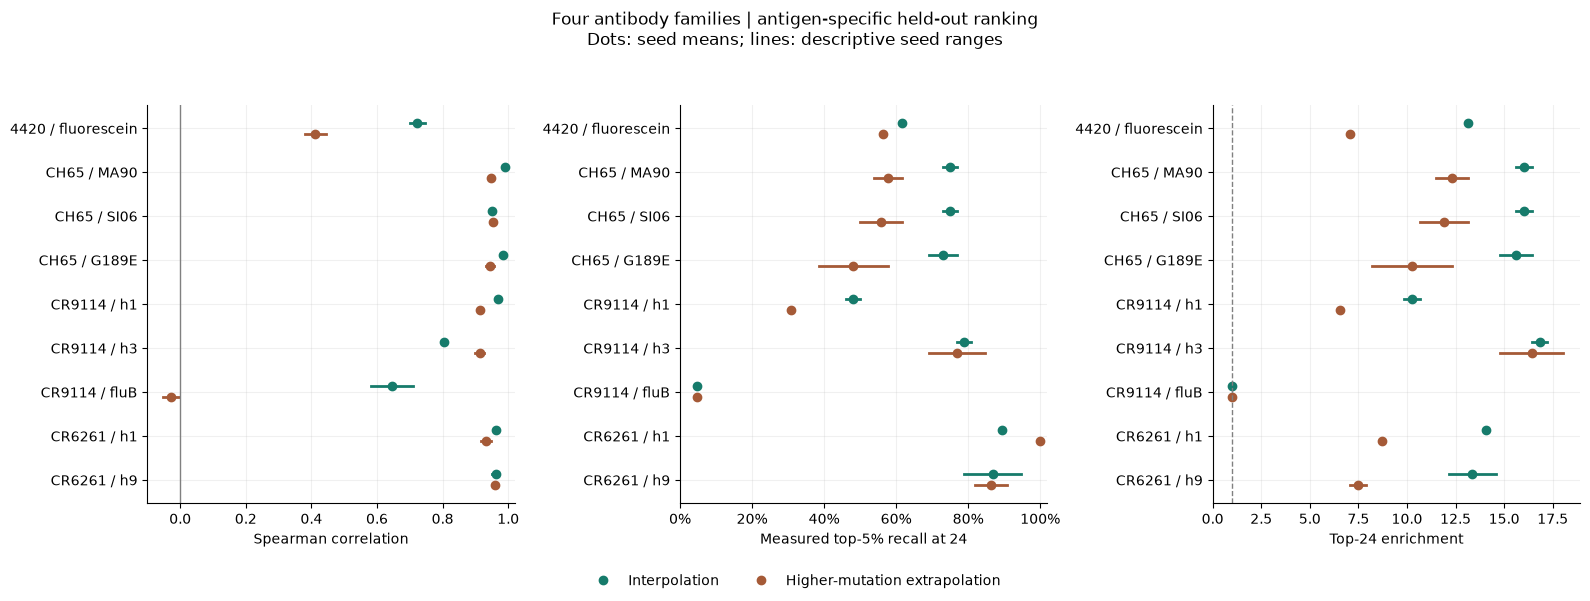

**Assay limits matter:** a large tie at the measured top-5% boundary expands the positive set. FluB has very few uncensored binders; top-5% recall can therefore include floor measurements. Constant true or predicted scores have undefined Spearman, rather than zero. Exact populations and uncensored-binder recall are saved in `benchmark_runs.csv`.

spearman_transfer_delta  \
task                     split                                             
ch65_full_g189e_binding  mutation_extrapolation                      0.0   
                         random                                      0.0   
ch65_full_ma90_binding   mutation_extrapolation                      0.0   
                         random                                      0.0   
ch65_full_si06_binding   mutation_extrapolation                      0.0   
                         random                                      0.0   
cr6261_full_h1_binding   mutation_extrapolation                      0.0   
                         random                                      0.0   
cr6261_full_h9_binding   mutation_extrapolation                      0.0   
                         random                                      0.0   
cr9114_full_flub_binding mutation_extrapolation                      0.0   
                         random                                      0.0   
cr9114_full_h1_binding   mutation_extrapolation                      0.0   
                         random                                      0.0   
cr9114_full_h3_binding   mutation_extrapolation                      0.0   
                         random                                      0.0   
titeseq_4420_binding     mutation_extrapolation                      0.0   
                         random                                      0.0   

                                                 top_recall_transfer_delta  \
task                     split                                               
ch65_full_g189e_binding  mutation_extrapolation                        0.0   
                         random                                        0.0   
ch65_full_ma90_binding   mutation_extrapolation                        0.0   
                         random                                        0.0   
ch65_full_si06_binding   mutation_extrapolation                        0.0   
                         random                                        0.0   
cr6261_full_h1_binding   mutation_extrapolation                        0.0   
                         random                                        0.0   
cr6261_full_h9_binding   mutation_extrapolation                        0.0   
                         random                                        0.0   
cr9114_full_flub_binding mutation_extrapolation                        0.0   
                         random                                        0.0   
cr9114_full_h1_binding   mutation_extrapolation                        0.0   
                         random                                        0.0   
cr9114_full_h3_binding   mutation_extrapolation                        0.0   
                         random                                        0.0   
titeseq_4420_binding     mutation_extrapolation                        0.0   
                         random                                        0.0   

                                                 top_enrichment_transfer_delta  
task                     split                                                  
ch65_full_g189e_binding  mutation_extrapolation                            0.0  
                         random                                            0.0  
ch65_full_ma90_binding   mutation_extrapolation                            0.0  
                         random                                            0.0  
ch65_full_si06_binding   mutation_extrapolation                            0.0  
                         random                                            0.0  
cr6261_full_h1_binding   mutation_extrapolation                            0.0  
                         random                                            0.0  
cr6261_full_h9_binding   mutation_extrapolation                            0.0  
                         random                                            0

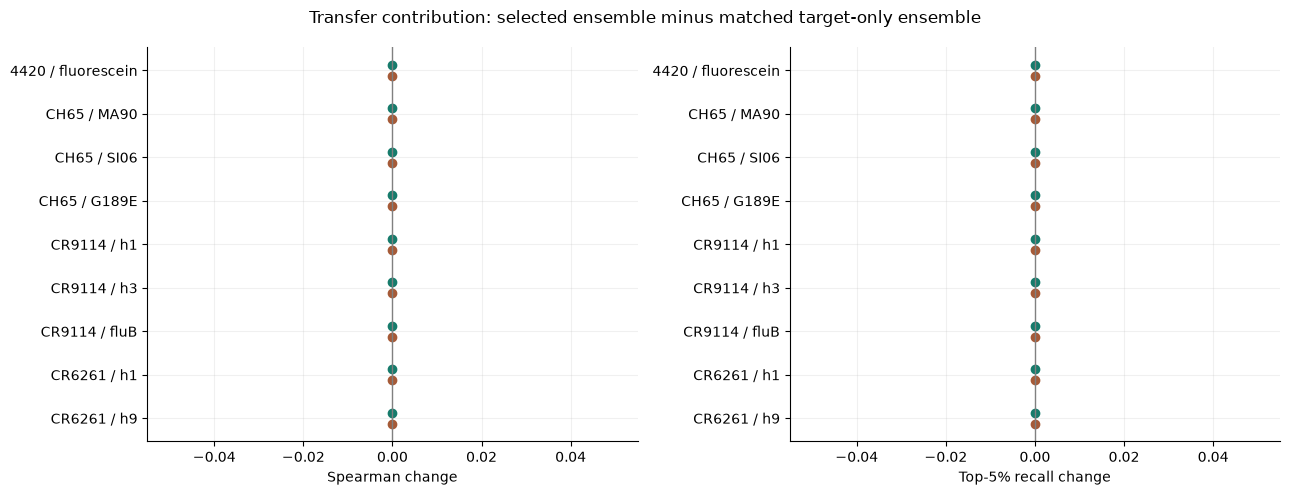

spearman_attention_delta  \
task                     split                                              
ch65_full_g189e_binding  mutation_extrapolation                     0.000   
                         random                                     0.004   
ch65_full_ma90_binding   mutation_extrapolation                     0.002   
                         random                                     0.000   
ch65_full_si06_binding   mutation_extrapolation                     0.000   
                         random                                     0.000   
cr6261_full_h1_binding   mutation_extrapolation                     0.000   
                         random                                     0.000   
cr6261_full_h9_binding   mutation_extrapolation                    -0.000   
                         random                                     0.000   
cr9114_full_flub_binding mutation_extrapolation                     0.000   
                         random                                     0.000   
cr9114_full_h1_binding   mutation_extrapolation                     0.012   
                         random                                     0.001   
cr9114_full_h3_binding   mutation_extrapolation                     0.000   
                         random                                     0.000   
titeseq_4420_binding     mutation_extrapolation                     0.000   
                         random                                     0.000   

                                                 top_recall_attention_delta  \
task                     split                                                
ch65_full_g189e_binding  mutation_extrapolation                       0.000   
                         random                                       0.038   
ch65_full_ma90_binding   mutation_extrapolation                       0.000   
                         random                                       0.000   
ch65_full_si06_binding   mutation_extrapolation                       0.000   
                         random                                       0.000   
cr6261_full_h1_binding   mutation_extrapolation                       0.000   
                         random                                       0.000   
cr6261_full_h9_binding   mutation_extrapolation                       0.045   
                         random                                       0.000   
cr9114_full_flub_binding mutation_extrapolation                       0.000   
                         random                                       0.000   
cr9114_full_h1_binding   mutation_extrapolation                       0.077   
                         random                                       0.038   
cr9114_full_h3_binding   mutation_extrapolation                       0.000   
                         random                                       0.000   
titeseq_4420_binding     mutation_extrapolation                       0.000   
                         random                                       0.000   

                                                 top_enrichment_attention_delta  
task                     split                                                   
ch65_full_g189e_binding  mutation_extrapolation                           0.000  
                         random                                           0.821  
ch65_full_ma90_binding   mutation_extrapolation                           0.000  
                         random                                           0.000  
ch65_full_si06_binding   mutation_extrapolation                           0.000  
                         random                                           0.000  
cr6261_full_h1_binding   mutation_extrapolation                           0.000  
                         random                                           0.000  
cr6261_full_h9_binding   mutation_extrapolation                           0.394  
                         

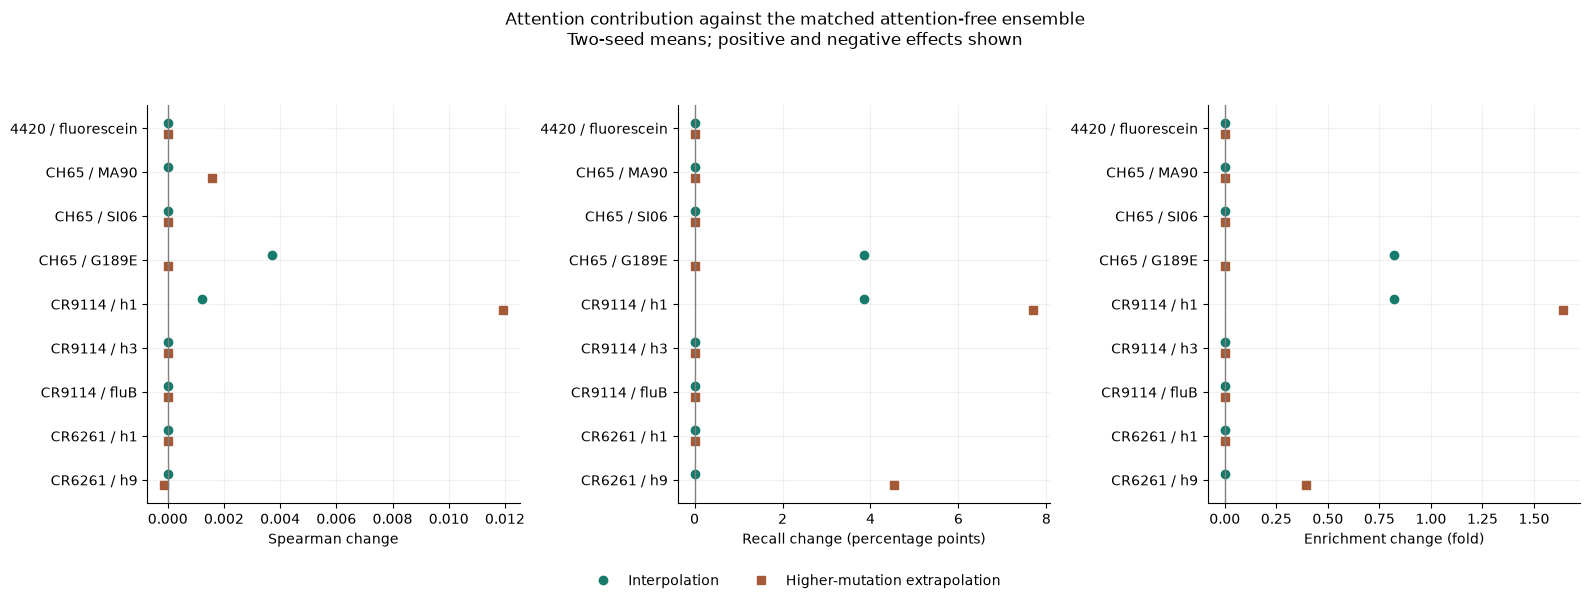

In [12]:
primary=summary[summary.model=='AeroFold'].copy()
labels={t:TASK_INFO[t]['family'].upper()+' / '+TASK_INFO[t]['antigen'] for t in BENCHMARK_TASKS}
fig,axes=plt.subplots(1,3,figsize=(16,6))
positions=np.arange(len(BENCHMARK_TASKS));colors={'random':'#167b6b','mutation_extrapolation':'#a55a37'}
names={'random':'Interpolation','mutation_extrapolation':'Higher-mutation extrapolation'}
for j,(metric,title) in enumerate([('spearman','Spearman correlation'),('top_recall','Measured top-5% recall at 24'),('top_enrichment','Top-24 enrichment')]):
    ax=axes[j]
    for k,split in enumerate(SPLITS):
        g=primary[primary.split==split].set_index('task').reindex(BENCHMARK_TASKS)
        yy=positions+(k-.5)*.25;values=g[f'{metric}_mean'].to_numpy()
        ax.plot(values,yy,'o',color=colors[split],label=names[split],markersize=6)
        for value,lo,hi,y in zip(values,g[f'{metric}_min'],g[f'{metric}_max'],yy):
            if np.isfinite(value):ax.plot([lo,hi],[y,y],color=colors[split],lw=2)
            else:ax.text(.02,y,'undefined correlation',va='center',fontsize=8)
        ax.set(yticks=positions,yticklabels=[labels[t] for t in BENCHMARK_TASKS],xlabel=title)
    ax.invert_yaxis()
    if j==0:ax.set_xlim(-.10,1.02);ax.axvline(0,color='grey',lw=1)
    elif j==1:ax.set_xlim(0,1.02)
    else:ax.set_xlim(left=0);ax.axvline(1,color='grey',ls='--',lw=1)
    if metric=='top_recall':ax.xaxis.set_major_formatter(PercentFormatter(1))
handles,legend=axes[0].get_legend_handles_labels();fig.legend(handles,legend,loc='lower center',ncol=2,frameon=False)
fig.suptitle('Four antibody families | antigen-specific held-out ranking\nDots: seed means; lines: descriptive seed ranges')
fig.tight_layout(rect=(0,.06,1,.94));fig.savefig(RESULTS_DIR/'benchmark_performance.png',dpi=160);plt.show()
display(Markdown('**Assay limits matter:** a large tie at the measured top-5% boundary expands the positive set. FluB has very few uncensored binders; top-5% recall can therefore include floor measurements. Constant true or predicted scores have undefined Spearman, rather than zero. Exact populations and uncensored-binder recall are saved in `benchmark_runs.csv`.'))

comparison=summary.pivot(index=['task','split'],columns='model',values='spearman_mean')
delta=pd.DataFrame(index=comparison.index)
for measure in ['spearman','top_recall','top_enrichment']:
    p=summary.pivot(index=['task','split'],columns='model',values=f'{measure}_mean')
    delta[measure+'_transfer_delta']=p['AeroFold']-p['Target-only ensemble']
delta.reset_index().to_csv(RESULTS_DIR/'transfer_contribution.csv',index=False)
display(delta.round(3))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,metric,label in zip(axes,['spearman','top_recall'],['Spearman change','Top-5% recall change']):
    for k,split in enumerate(SPLITS):
        values=delta.xs(split,level='split').reindex(BENCHMARK_TASKS)[metric+'_transfer_delta']
        ax.plot(values,positions+(k-.5)*.25,'o',color=colors[split],label=names[split])
    ax.axvline(0,color='grey',lw=1);ax.set(yticks=positions,yticklabels=[labels[t] for t in BENCHMARK_TASKS],xlabel=label);ax.invert_yaxis()
fig.suptitle('Transfer contribution: selected ensemble minus matched target-only ensemble')
fig.tight_layout();fig.savefig(RESULTS_DIR/'transfer_contribution.png',dpi=160);plt.show()


attention_delta=[]
for measure in ['spearman','top_recall','top_enrichment']:
    p=summary.pivot(index=['task','split'],columns='model',values=f'{measure}_mean')
    attention_delta.append((p['AeroFold']-p['Attention-free ensemble']).rename(measure+'_attention_delta'))
attention_delta=pd.concat(attention_delta,axis=1)
attention_delta.reset_index().to_csv(RESULTS_DIR/'attention_contribution.csv',index=False)
display(attention_delta.round(3))
fig,axes=plt.subplots(1,3,figsize=(16,6))
for ax,metric,label in zip(axes,['spearman','top_recall','top_enrichment'],
        ['Spearman change','Recall change (percentage points)','Enrichment change (fold)']):
    for k,split in enumerate(SPLITS):
        values=attention_delta.xs(split,level='split').reindex(BENCHMARK_TASKS)[metric+'_attention_delta']
        if metric=='top_recall':values=100*values
        ax.plot(values,positions+(k-.5)*.25,'o' if k==0 else 's',color=colors[split],label=names[split])
    ax.axvline(0,color='grey',lw=1)
    ax.set(yticks=positions,yticklabels=[labels[t] for t in BENCHMARK_TASKS],xlabel=label);ax.invert_yaxis()
handles,legend=axes[0].get_legend_handles_labels()
fig.legend(handles,legend,loc='lower center',ncol=2,frameon=False)
fig.suptitle('Attention contribution against the matched attention-free ensemble\nTwo-seed means; positive and negative effects shown')
fig.tight_layout(rect=(0,.06,1,.94));fig.savefig(RESULTS_DIR/'attention_contribution.png',dpi=160);plt.show()


### 11. Fit every production model on all its measurements
Evaluation is complete before these models are fitted. Training predictions from these artifacts are not benchmark evidence. Reusable pickle artifacts contain selected experts and the supervised source checkpoint needed for inference.

In [13]:
models={};final_selections=[];final_validations=[]
if TRAIN_FINAL_MODELS:
    for task in FINAL_TASKS:
        frame=data[task];print(f'Final fitting {task}: all {len(frame):,} measured variants',flush=True)
        model=AeroFoldTransferEnsemble(task,checkpoints[TASK_INFO[task]['family']],PRODUCTION_SEED).fit(frame.to_dict('records'),frame.score.to_numpy(float),embeddings.get(task))
        model_path=RESULTS_DIR/f'{task}_model.pkl'
        with model_path.open('wb') as stream:cloudpickle.dump(model,stream)
        card=model.card();card.update(code_sha256=CODE_HASH,artifact_sha256=hashlib.sha256(model_path.read_bytes()).hexdigest(),source=source_audit.set_index('task').loc[task].to_dict())
        (RESULTS_DIR/f'{task}_model_card.json').write_text(json.dumps(card,indent=2,allow_nan=False),encoding='utf8')
        final_selections.append(model.selection_summary.assign(task=task));final_validations.append(model.validation.assign(task=task))
        models[task]=model
    pd.concat(final_selections).to_csv(RESULTS_DIR/'final_selection.csv',index=False)
    pd.concat(final_validations).to_csv(RESULTS_DIR/'final_validation.csv',index=False)
    selected=pd.concat(final_selections)
    display(selected[selected.weight>0][['task','regime','spec','weight','floor_cut']])



Final fitting titeseq_4420_binding: all 2,807 measured variants


Final fitting ch65_full_ma90_binding: all 65,530 measured variants


Final fitting ch65_full_si06_binding: all 64,619 measured variants


Final fitting ch65_full_g189e_binding: all 63,840 measured variants


Final fitting cr9114_full_h1_binding: all 65,094 measured variants


Final fitting cr9114_full_h3_binding: all 65,535 measured variants


Final fitting cr9114_full_flub_binding: all 65,534 measured variants


Final fitting cr6261_full_h1_binding: all 1,887 measured variants


Final fitting cr6261_full_h9_binding: all 1,842 measured variants


,task,regime,spec,weight,floor_cut
3,titeseq_4420_binding,interpolation,"('sequence', 'ordinal', 0.1)",0.80,0.55
9,titeseq_4420_binding,interpolation,"('sequence', 'pairwise', 1.0)",0.20,0.55
36,titeseq_4420_binding,extrapolation,"('sequence', 'pairwise', 1.0)",0.60,0.55
40,titeseq_4420_binding,extrapolation,"('pair', 'global', 0.1)",0.40,0.55
17,ch65_full_ma90_binding,interpolation,"('categorical', 'boost', 15)",1.00,0.00
42,ch65_full_ma90_binding,extrapolation,"('categorical', 'boost', 15)",1.00,0.00
17,ch65_full_si06_binding,interpolation,"('categorical', 'boost', 15)",1.00,0.40
41,ch65_full_si06_binding,extrapolation,"('categorical', 'boost', 7)",0.20,0.00
42,ch65_full_si06_binding,extrapolation,"('categorical', 'boost', 15)",0.80,0.00
17,ch65_full_g189e_binding,interpolation,"('categorical', 'boost', 15)",1.00,0.00


### 12. Rank new candidates
Set `CANDIDATE_TASK` and `CANDIDATES_CSV` in Setup. Candidate columns are `variant_id,heavy_sequence,light_sequence`, with complete canonical domains matching the chosen family reference layout. Ranking scores are higher-is-better and dimensionless; estimated assay scores are approximate mappings from internal validation. Known measurements are flagged. Models are specific to the named antigen; these are not new-antigen predictors.

In [14]:
def candidate_embeddings(task,candidates):
    if task not in embeddings:return None
    lookup=dict(zip(data[task].key,range(len(data[task]))))
    matrix=embeddings[task];keys=[fingerprint(r) for r in candidates.to_dict('records')]
    result=np.empty((len(candidates),matrix.shape[1]));unknown=[]
    for i,key in enumerate(keys):
        if key in lookup:result[i]=matrix[lookup[key]]
        else:unknown.append(i)
    if unknown:
        import ablang2
        weights=Path(ablang2.__file__).parent/'model-weights-ablang2-paired/model.pt'
        if not weights.exists():raise ValueError('Novel candidate encoding requires the local verified AbLang-2 weights')
        encoder=ablang2.pretrained(model_to_use='ablang2-paired',random_init=False,ncpu=2,device='cpu')
        for start in range(0,len(unknown),16):
            ix=unknown[start:start+16];rows=candidates.iloc[ix].to_dict('records')
            pairs=[[r['heavy_sequence'],r['light_sequence']] for r in rows]
            with torch.inference_mode():result[ix]=np.asarray(encoder(pairs,mode='seqcoding',batch_size=16),float).reshape(len(ix),-1)
    return result

def rank_candidates(task,path):
    if task not in TASK_INFO:raise ValueError('Choose a known antibody/antigen task')
    if task not in models:
        with (RESULTS_DIR/f'{task}_model.pkl').open('rb') as stream:models[task]=cloudpickle.load(stream)
    model=models[task];frame=pd.read_csv(path,keep_default_na=False)
    required={'variant_id','heavy_sequence','light_sequence'}
    if required-set(frame) or frame.empty or not frame.variant_id.is_unique:raise ValueError('Provide nonempty canonical sequences with unique variant IDs')
    residue_codes(frame.to_dict('records'))
    if any(not 70<=len(s)<=180 for s in frame.heavy_sequence):raise ValueError('Provide complete heavy variable domains')
    e=candidate_embeddings(task,frame) if model.needs_embedding else None
    out=frame[['variant_id','heavy_sequence','light_sequence']].copy()
    for key,value in model.predict(frame.to_dict('records'),e).items():out[key]=value
    keys=[fingerprint(r) for r in frame.to_dict('records')];known=dict(zip(data[task].key,data[task].score))
    out['already_measured']=[k in known for k in keys];out['measured_score']=[known.get(k,np.nan) for k in keys]
    out['used_for_training']=[k in set(model.training_keys) for k in keys]
    out=out.sort_values('rank_score',ascending=False,kind='stable').reset_index(drop=True)
    out['screening_rank']=np.arange(1,len(out)+1)
    out.to_csv(RESULTS_DIR/f'{task}_candidate_rankings.csv',index=False);return out

if CANDIDATES_CSV is not None:display(rank_candidates(CANDIDATE_TASK,CANDIDATES_CSV).head(24))
else:print('Final artifacts are ready. Set CANDIDATES_CSV and CANDIDATE_TASK to rank your own variants.')


Final artifacts are ready. Set CANDIDATES_CSV and CANDIDATE_TASK to rank your own variants.


### 13. Verify evidence and saved artifacts

In [15]:
for item in source_audit.to_dict('records'):
    assert hashlib.sha256((ROOT/item['source']).read_bytes()).hexdigest()==item['sha256']
for checkpoint in checkpoints.values():
    assert checkpoint['training_device'].startswith('cuda') and checkpoint['peak_gpu_memory_mb']>0
    assert all(s['family']!=checkpoint['excluded_family'] for s in checkpoint['source_tasks'])
    source_keys=set().union(*(set(data[s['task']].key) for s in checkpoint['source_tasks']))
    target_keys=set().union(*(set(data[t].key) for t in data if TASK_INFO[t]['family']==checkpoint['excluded_family']))
    assert not source_keys&target_keys
for split,card in zip(split_audit,cards):
    training,test=set(split['training_keys']),set(split['test_keys'])
    assert not training&test
    assert training==set(card['training_keys'])
    for fold in card['folds']:
        a,b=set(fold['training_keys']),set(fold['validation_keys'])
        assert not a&b and not (a|b)&test and a|b<=training
for row in runs.to_dict('records'):
    assert np.isclose(row['top_enrichment'],row['top_recall']/row['random_recall'])
    p=predictions[(predictions.task==row['task'])&(predictions.split==row['split'])&(predictions.seed==row['seed'])&(predictions.model==row['model'])]
    threshold=np.sort(p.truth.to_numpy())[-math.ceil(.05*len(p))]
    positive=p.truth>=threshold;chosen=p.rank_score.sort_values(ascending=False,kind='stable').index[:TOP_K]
    hits=int(positive.loc[chosen].sum())
    assert hits==row['top_hits'] and int(positive.sum())==row['top_population']
for task,model in models.items():
    attention=model.fitted[model.control_heads['Attention only']][0]
    assert attention.training_device.startswith('cuda') and attention.peak_gpu_memory_mb>0
    path=RESULTS_DIR/f'{task}_model.pkl'
    with path.open('rb') as stream:restored=cloudpickle.load(stream)
    frame=data[task].iloc[:12];e=embeddings.get(task);e=None if e is None else e[:12]
    p=restored.predict(frame.to_dict('records'),e)['rank_score']
    np.testing.assert_array_equal(p,model.predict(frame.to_dict('records'),e)['rank_score'])
    np.testing.assert_allclose(p[:1],restored.predict(frame.iloc[:1].to_dict('records'),None if e is None else e[:1])['rank_score'],atol=1e-6)
    assert set(model.training_keys)==set(data[task].key)
assert np.isfinite(predictions.rank_score).all()
validation=dict(status='passed',code_sha256=CODE_HASH,neural_training_device=str(DEVICE),gpu_name=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,cuda_version=torch.version.cuda,outer_runs=len(runs),assays=len(data),families=4,
    source_hashes='passed',family_exclusion='passed',fold_separation='passed',independent_hit_counts='passed',
    artifact_roundtrips='passed',query_batch_independence='passed',attention_ablation='matched same folds and objective',packages={p:importlib.metadata.version(p) for p in ['numpy','pandas','scipy','scikit-learn','torch','biopython','lightgbm','cloudpickle','nbformat']})
(RESULTS_DIR/'validation.json').write_text(json.dumps(validation,indent=2),encoding='utf8')
print('Passed: provenance, transfer exclusions, fold separation, independent metric arithmetic, saved-artifact predictions and batch invariance.')


Passed: provenance, transfer exclusions, fold separation, independent metric arithmetic, saved-artifact predictions and batch invariance.


## Takeaways

In [16]:
lines=['# Executed multi-family model findings',
    'Separate antigen-specific models; supervised transfer excludes the complete benchmark antibody family.']
for row in primary.to_dict('records'):
    lines.append(f"- {row['task']} / {names.get(row['split'],row['split']) if isinstance(names,dict) else row['split']}: Spearman {row['spearman_mean']:.3f}, continuous Spearman {row['latent_spearman_mean']:.3f}, measured top-5% recall {row['top_recall_mean']:.1%}, enrichment {row['top_enrichment_mean']:.2f}x.")
lines += ['', 'Attention and source transfer can help, receive zero weight, or reduce individual metrics. Inspect the matched attention-free and target-only comparisons.',
    'Top-5% labels are tie-inclusive. Floor-dominated assays may expand this set far beyond 5%; uncensored-binder recall is reported separately.',
    'Undefined correlations identify constant test labels. Public-library results do not establish prospective or universal superiority.',
    'Final production models fit all finite measured variants after evaluation. The frozen source checkpoints contain only other antibody families.']
findings='\n'.join(lines);(RESULTS_DIR/'findings.md').write_text(findings,encoding='utf8');display(Markdown(findings))


# Executed multi-family model findings
Separate antigen-specific models; supervised transfer excludes the complete benchmark antibody family.
- titeseq_4420_binding / Interpolation: Spearman 0.723, continuous Spearman 0.643, measured top-5% recall 61.5%, enrichment 13.13x.
- titeseq_4420_binding / Higher-mutation extrapolation: Spearman 0.412, continuous Spearman 0.309, measured top-5% recall 56.2%, enrichment 7.08x.
- ch65_full_ma90_binding / Interpolation: Spearman 0.989, continuous Spearman 0.989, measured top-5% recall 75.0%, enrichment 16.00x.
- ch65_full_ma90_binding / Higher-mutation extrapolation: Spearman 0.948, continuous Spearman 0.948, measured top-5% recall 57.7%, enrichment 12.31x.
- ch65_full_si06_binding / Interpolation: Spearman 0.949, continuous Spearman 0.930, measured top-5% recall 75.0%, enrichment 16.00x.
- ch65_full_si06_binding / Higher-mutation extrapolation: Spearman 0.954, continuous Spearman 0.954, measured top-5% recall 55.8%, enrichment 11.90x.
- ch65_full_g189e_binding / Interpolation: Spearman 0.985, continuous Spearman 0.985, measured top-5% recall 73.1%, enrichment 15.59x.
- ch65_full_g189e_binding / Higher-mutation extrapolation: Spearman 0.944, continuous Spearman 0.944, measured top-5% recall 48.1%, enrichment 10.26x.
- cr9114_full_h1_binding / Interpolation: Spearman 0.968, continuous Spearman 0.968, measured top-5% recall 48.1%, enrichment 10.26x.
- cr9114_full_h1_binding / Higher-mutation extrapolation: Spearman 0.913, continuous Spearman 0.913, measured top-5% recall 30.8%, enrichment 6.56x.
- cr9114_full_h3_binding / Interpolation: Spearman 0.805, continuous Spearman 0.505, measured top-5% recall 78.8%, enrichment 16.82x.
- cr9114_full_h3_binding / Higher-mutation extrapolation: Spearman 0.913, continuous Spearman 0.847, measured top-5% recall 76.9%, enrichment 16.41x.
- cr9114_full_flub_binding / Interpolation: Spearman 0.645, continuous Spearman 0.146, measured top-5% recall 4.7%, enrichment 1.00x.
- cr9114_full_flub_binding / Higher-mutation extrapolation: Spearman -0.028, continuous Spearman -0.028, measured top-5% recall 4.7%, enrichment 1.00x.
- cr6261_full_h1_binding / Interpolation: Spearman 0.963, continuous Spearman 0.963, measured top-5% recall 89.5%, enrichment 14.09x.
- cr6261_full_h1_binding / Higher-mutation extrapolation: Spearman 0.931, continuous Spearman 0.931, measured top-5% recall 100.0%, enrichment 8.71x.
- cr6261_full_h9_binding / Interpolation: Spearman 0.962, continuous Spearman 0.962, measured top-5% recall 86.8%, enrichment 13.35x.
- cr6261_full_h9_binding / Higher-mutation extrapolation: Spearman 0.960, continuous Spearman 0.960, measured top-5% recall 86.4%, enrichment 7.48x.

Attention and source transfer can help, receive zero weight, or reduce individual metrics. Inspect the matched attention-free and target-only comparisons.
Top-5% labels are tie-inclusive. Floor-dominated assays may expand this set far beyond 5%; uncensored-binder recall is reported separately.
Undefined correlations identify constant test labels. Public-library results do not establish prospective or universal superiority.
Final production models fit all finite measured variants after evaluation. The frozen source checkpoints contain only other antibody families.